In [ ]:

import pandas as pd
from pathlib import Path

# Locate the project folder from the current working directory
current_dir = Path.cwd()

if (current_dir / "Data").is_dir():
    project_dir = current_dir
elif (current_dir.parent / "Data").is_dir():
    project_dir = current_dir.parent
else:
    raise FileNotFoundError(
        "Could not find the project Data folder. "
        "Open Jupyter from the project or Notebook directory."
    )

# Set input and output directories
data_dir = project_dir / "Data"
output_dir = project_dir / "Data_Cleaned"

# Locate the AIHW Excel workbook
file_path = data_dir / "myhosp-emergency-department-data-extract.xlsx"

if not file_path.is_file():
    raise FileNotFoundError(f"Workbook not found: {file_path}")

# Display the available Excel worksheets
excel_file = pd.ExcelFile(file_path)

print("Project directory:", project_dir)
print("Available worksheets:")

for sheet in excel_file.sheet_names:
    print("-", sheet)

Available worksheets:
- Patients seen on time
- Time in ED - within 4 hrs
- Time in ED
- Presentations


In [2]:
# Load the Presentations worksheet
presentations = pd.read_excel(
    file_path,
    sheet_name="Presentations"
)

# Display the size of the dataset
print("Dataset shape:", presentations.shape)

# Display the column names
print("\nColumn names:")
print(presentations.columns.tolist())

# Display the first 10 rows
display(presentations.head(10))

Dataset shape: (22693, 6)

Column names:
['Unnamed: 0', 'www.aihw.gov.au\nAustralian Institute of Health and Welfare\nGPO Box 570, Canberra ACT 2601, Australia', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']


,Unnamed: 0,"www.aihw.gov.au\nAustralian Institute of Health and Welfare\nGPO Box 570, Canberra ACT 2601, Australia",Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
0,Time spent in emergency departments,NaN,NaN,NaN,NaN,NaN
1,Measure: Total emergency department presentations,NaN,NaN,NaN,NaN,NaN
2,"Data as of: Wednesday, August 19, 2026, versio...",NaN,NaN,NaN,NaN,NaN
3,The number of presentations (visits) to this h...,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN
5,Explanatory notes,NaN,NaN,Triage 1. Resuscitation (requires immediate tr...,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,NaN,NaN,Triage 2. Emergency (treatment required within...,NaN,NaN
8,NaN,NaN,NaN,Triage 3. Urgent (treatment required within 30...,NaN,NaN
9,NaN,NaN,NaN,Triage 4. Semi-urgent (treatment required with...,NaN,NaN


In [3]:
# Display rows 10 to 35 to identify the actual data headers
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

display(presentations.iloc[10:35])

,Unnamed: 0,"www.aihw.gov.au\nAustralian Institute of Health and Welfare\nGPO Box 570, Canberra ACT 2601, Australia",Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5
10,NaN,NaN,NaN,Triage 5. Non-urgent (treatment recommended within 120 minutes),NaN,NaN
11,NaN,NaN,NaN,NaN,NaN,NaN
12,"Excludes data for the Australian Capital Territory in 2015–16, which were not available for publ...",NaN,NaN,NaN,NaN,NaN
13,NaN,NaN,NaN,NaN,NaN,NaN
14,Reporting unit,Reporting unit type,State,Year,Triage category,Number of presentations
15,National,National,NAT,2011–12,Emergency,647788
16,National,National,NAT,2012–13,Emergency,714124
17,National,National,NAT,2013–14,Emergency,785791
18,National,National,NAT,2014–15,Emergency,843443
19,National,National,NAT,2015–16,Emergency,899906


In [4]:
# Reload the Presentations worksheet using the correct header row
presentations_clean = pd.read_excel(
    file_path,
    sheet_name="Presentations",
    header=15
)

# Display the dataset dimensions
print("Dataset shape:", presentations_clean.shape)

# Display the column names
print("\nColumn names:")
print(presentations_clean.columns.tolist())

# Preview the first 10 rows
display(presentations_clean.head(10))

Dataset shape: (22678, 6)

Column names:
['Reporting unit', 'Reporting unit type', 'State', 'Year', 'Triage category', 'Number of presentations']


,Reporting unit,Reporting unit type,State,Year,Triage category,Number of presentations
0,National,National,NAT,2011–12,Emergency,647788
1,National,National,NAT,2012–13,Emergency,714124
2,National,National,NAT,2013–14,Emergency,785791
3,National,National,NAT,2014–15,Emergency,843443
4,National,National,NAT,2015–16,Emergency,899906
5,National,National,NAT,2016–17,Emergency,970883
6,National,National,NAT,2017–18,Emergency,1043705
7,National,National,NAT,2018–19,Emergency,1136383
8,National,National,NAT,2019–20,Emergency,1158156
9,National,National,NAT,2020–21,Emergency,1256584


In [ ]:
# Examine data quality and structure

# 1. Check column data types
print("DATA TYPES:")
print(presentations_clean.dtypes)

# 2. Check missing values
print("\nMISSING VALUES:")
print(presentations_clean.isnull().sum())

# 3. Check reporting years
print("\nREPORTING YEARS:")
print(presentations_clean["Year"].unique())

# 4. Check reporting unit types
print("\nREPORTING UNIT TYPES:")
print(presentations_clean["Reporting unit type"].value_counts(dropna=False))

# 5. Check triage categories
print("\nTRIAGE CATEGORIES:")
print(presentations_clean["Triage category"].value_counts(dropna=False))

# 6. Check state codes
print("\nSTATES:")
print(presentations_clean["State"].value_counts(dropna=False))

DATA TYPES:
Reporting unit                str
Reporting unit type           str
State                         str
Year                          str
Triage category               str
Number of presentations    object
dtype: object

MISSING VALUES:
Reporting unit             0
Reporting unit type        0
State                      0
Year                       0
Triage category            0
Number of presentations    0
dtype: int64

REPORTING YEARS:
<StringArray>
['2011–12', '2012–13', '2013–14', '2014–15', '2015–16', '2016–17', '2017–18',
 '2018–19', '2019–20', '2020–21', '2021–22', '2022–23', '2023–24', '2024–25']
Length: 14, dtype: str

REPORTING UNIT TYPES:
Reporting unit type
Hospital                  19375
Local Hospital Network     2678
State                       555
National                     70
Name: count, dtype: int64

TRIAGE CATEGORIES:
Triage category
Emergency        4537
Non-Urgent       4537
Semi-Urgent      4537
Urgent           4537
Resuscitation    4530
Name: count,

In [7]:
# Check which DataFrames are currently available
%whos DataFrame

Variable              Type         Data/Info
--------------------------------------------
presentations         DataFrame    Shape: (22693, 6)
presentations_clean   DataFrame    Shape: (22678, 6)


In [ ]:
# Investigate non-numeric presentation values

# Convert values to numeric temporarily
numeric_values = pd.to_numeric(
    presentations_clean["Number of presentations"],
    errors="coerce"
)

# Identify rows containing non-numeric values
non_numeric_rows = presentations_clean[
    numeric_values.isna()
]

# Display results
print("Total rows:", len(presentations_clean))
print("Non-numeric rows:", len(non_numeric_rows))

print("\nUnique non-numeric values:")
print(
    non_numeric_rows["Number of presentations"]
    .value_counts(dropna=False)
)


Total rows: 22678
Non-numeric rows: 616

Unique non-numeric values:
Number of presentations
<5    616
Name: count, dtype: int64


In [10]:
# Convert presentation counts to numeric values
presentations_clean["Presentations_numeric"] = pd.to_numeric(
    presentations_clean["Number of presentations"],
    errors="coerce"
)

# Check numeric conversion results
print("Total records:", len(presentations_clean))
print("Valid numeric records:", presentations_clean["Presentations_numeric"].notna().sum())
print("Suppressed records:", presentations_clean["Presentations_numeric"].isna().sum())

# Preview the updated dataset
presentations_clean.head()

Total records: 22678
Valid numeric records: 22062
Suppressed records: 616


,Reporting unit,Reporting unit type,State,Year,Triage category,Number of presentations,Presentations_numeric
0,National,National,NAT,2011–12,Emergency,647788,647788.0
1,National,National,NAT,2012–13,Emergency,714124,714124.0
2,National,National,NAT,2013–14,Emergency,785791,785791.0
3,National,National,NAT,2014–15,Emergency,843443,843443.0
4,National,National,NAT,2015–16,Emergency,899906,899906.0


In [11]:
# Examine the reporting levels in the dataset
print("Reporting unit types:")
print(presentations_clean["Reporting unit type"].value_counts())

# Count unique reporting units within each type
print("\nUnique reporting units by type:")
print(
    presentations_clean.groupby("Reporting unit type")["Reporting unit"]
    .nunique()
)

Reporting unit types:
Reporting unit type
Hospital                  19375
Local Hospital Network     2678
State                       555
National                     70
Name: count, dtype: int64

Unique reporting units by type:
Reporting unit type
Hospital                  311
Local Hospital Network     82
National                    1
State                       8
Name: Reporting unit, dtype: int64


In [12]:
# Identify available triage categories
print("Triage categories:")
print(presentations_clean["Triage category"].value_counts())

# Examine triage categories at the national level
print("\nNational-level triage categories:")
print(
    presentations_clean[
        presentations_clean["Reporting unit type"] == "National"
    ]["Triage category"].value_counts()
)

Triage categories:
Triage category
Emergency        4537
Non-Urgent       4537
Semi-Urgent      4537
Urgent           4537
Resuscitation    4530
Name: count, dtype: int64

National-level triage categories:
Triage category
Emergency        14
Non-Urgent       14
Resuscitation    14
Semi-Urgent      14
Urgent           14
Name: count, dtype: int64


In [13]:
# Filter national-level emergency department records
national_data = presentations_clean[
    presentations_clean["Reporting unit type"] == "National"
].copy()

# Check national data completeness
print("Total national records:", len(national_data))
print("Unique reporting years:", national_data["Year"].nunique())
print("Suppressed national records:", national_data["Presentations_numeric"].isna().sum())

# Display national presentation counts by year and triage category
display(
    national_data.pivot(
        index="Year",
        columns="Triage category",
        values="Presentations_numeric"
    )
)

Total national records: 70
Unique reporting years: 14
Suppressed national records: 0


Triage category,Emergency,Non-Urgent,Resuscitation,Semi-Urgent,Urgent
Year,,,,,
2011–12,647788.0,724396.0,42634.0,2923231.0,2200172.0
2012–13,714124.0,669604.0,45292.0,2971536.0,2310691.0
2013–14,785791.0,791763.0,46741.0,3100559.0,2464328.0
2014–15,843443.0,759209.0,49035.0,3130356.0,2578398.0
2015–16,899906.0,712021.0,52718.0,3110520.0,2686516.0
2016–17,970883.0,719148.0,56543.0,3153383.0,2851977.0
2017–18,1043705.0,705993.0,60642.0,3201449.0,3002488.0
2018–19,1136383.0,695831.0,64515.0,3275094.0,3176986.0
2019–20,1158156.0,731798.0,66532.0,3127982.0,3148837.0


## National Emergency Department Demand Analysis

### Annual Emergency Department Presentations

In [14]:
# Calculate total emergency department presentations by financial year
annual_presentations = (
    national_data.groupby("Year")["Presentations_numeric"]
    .sum()
    .reset_index()
)

# Rename the total presentations column
annual_presentations.rename(
    columns={"Presentations_numeric": "Total_presentations"},
    inplace=True
)

# Display annual presentation totals
display(annual_presentations)

,Year,Total_presentations
0,2011–12,6538221.0
1,2012–13,6711247.0
2,2013–14,7189182.0
3,2014–15,7360441.0
4,2015–16,7461681.0
5,2016–17,7751934.0
6,2017–18,8014277.0
7,2018–19,8348809.0
8,2019–20,8233305.0
9,2020–21,8805465.0


### Trend in Annual Emergency Department Presentations

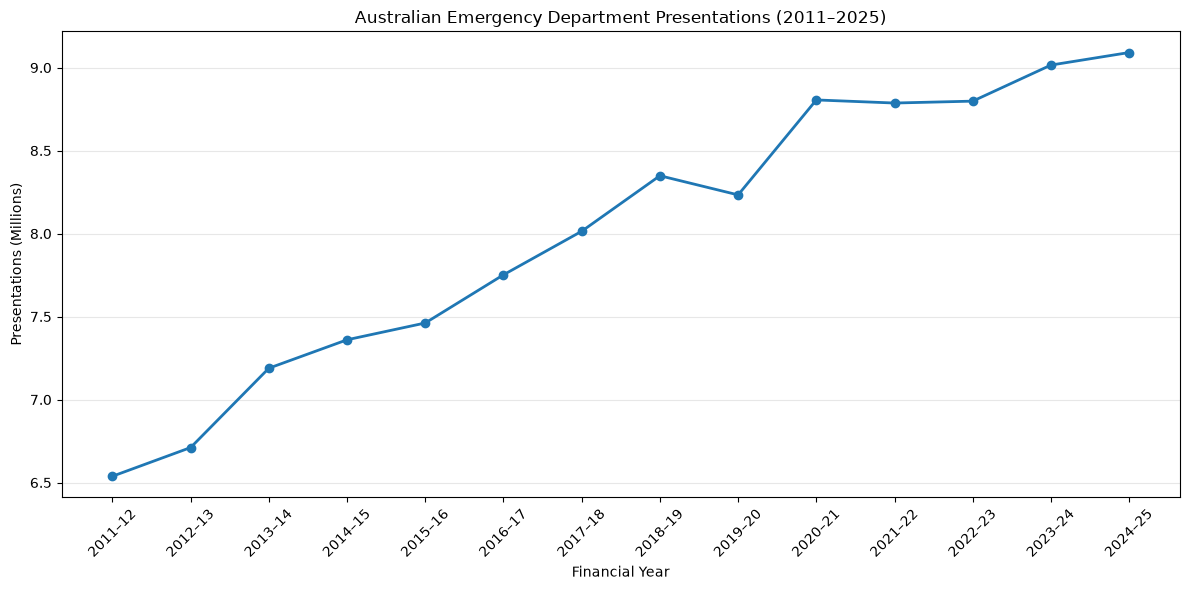

In [16]:
import matplotlib.pyplot as plt

# Visualise annual emergency department presentations
plt.figure(figsize=(12, 6))

plt.plot(
    annual_presentations["Year"],
    annual_presentations["Total_presentations"] / 1_000_000,
    marker="o",
    linewidth=2
)

plt.title("Australian Emergency Department Presentations (2011–2025)")
plt.xlabel("Financial Year")
plt.ylabel("Presentations (Millions)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Year-over-Year Growth in Emergency Department Presentations

In [17]:

# Calculate annual percentage change in presentations
annual_presentations["YoY_growth_pct"] = (
    annual_presentations["Total_presentations"]
    .pct_change() * 100
)

# Round percentage changes to two decimal places
annual_presentations["YoY_growth_pct"] = (
    annual_presentations["YoY_growth_pct"].round(2)
)

# Display annual totals and growth rates
display(annual_presentations)


,Year,Total_presentations,YoY_growth_pct
0,2011–12,6538221.0,NaN
1,2012–13,6711247.0,2.65
2,2013–14,7189182.0,7.12
3,2014–15,7360441.0,2.38
4,2015–16,7461681.0,1.38
5,2016–17,7751934.0,3.89
6,2017–18,8014277.0,3.38
7,2018–19,8348809.0,4.17
8,2019–20,8233305.0,-1.38
9,2020–21,8805465.0,6.95


### Annual Growth Rate in Emergency Department Presentations

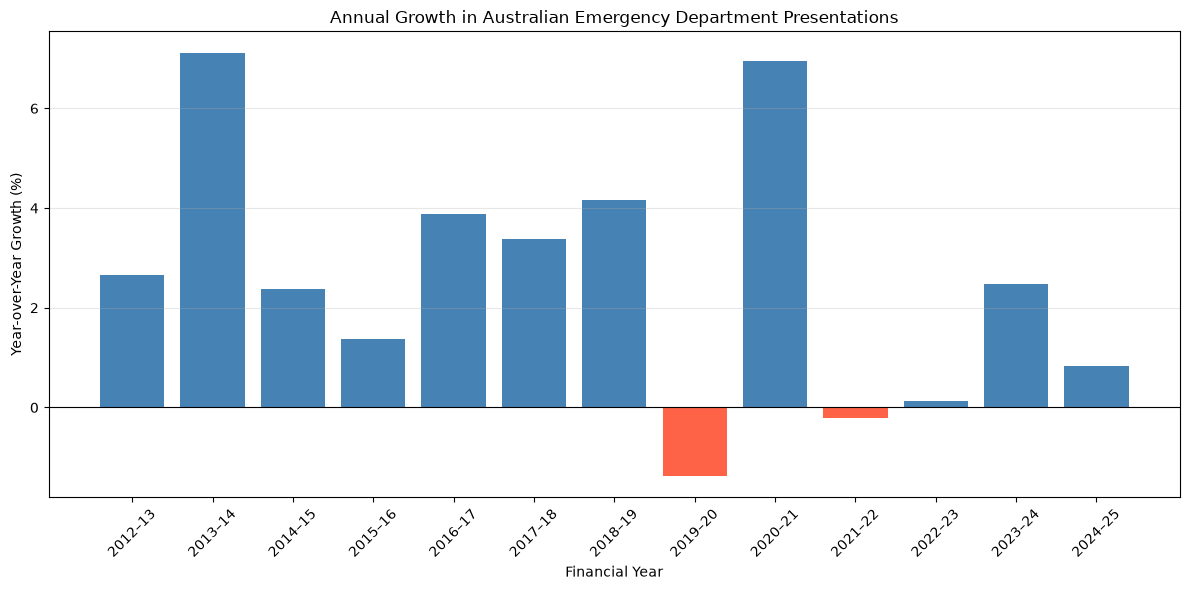

In [18]:
# Visualise annual percentage changes in ED presentations
growth_data = annual_presentations.dropna(
    subset=["YoY_growth_pct"]
)

plt.figure(figsize=(12, 6))

plt.bar(
    growth_data["Year"],
    growth_data["YoY_growth_pct"],
    color=[
        "steelblue" if value >= 0 else "tomato"
        for value in growth_data["YoY_growth_pct"]
    ]
)

plt.axhline(0, color="black", linewidth=0.8)

plt.title("Annual Growth in Australian Emergency Department Presentations")
plt.xlabel("Financial Year")
plt.ylabel("Year-over-Year Growth (%)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Emergency Department Demand by Triage Category

### Triage Category Distribution (2024–25)

In [19]:
# Filter national presentations for the latest financial year
triage_2024 = national_data[
    national_data["Year"] == "2024–25"
].copy()

# Calculate presentations by triage category
triage_summary = (
    triage_2024.groupby("Triage category")["Presentations_numeric"]
    .sum()
    .reset_index()
)

# Calculate each category's share of total presentations
triage_summary["Percentage"] = (
    triage_summary["Presentations_numeric"]
    / triage_summary["Presentations_numeric"].sum() * 100
).round(2)

# Sort categories by presentation volume
triage_summary = triage_summary.sort_values(
    "Presentations_numeric",
    ascending=False
)

display(triage_summary)

,Triage category,Presentations_numeric,Percentage
4,Urgent,3789676.0,41.69
3,Semi-Urgent,3050990.0,33.56
0,Emergency,1608414.0,17.69
1,Non-Urgent,555221.0,6.11
2,Resuscitation,86831.0,0.96


### Emergency Department Presentations by Triage Category (2024–25)

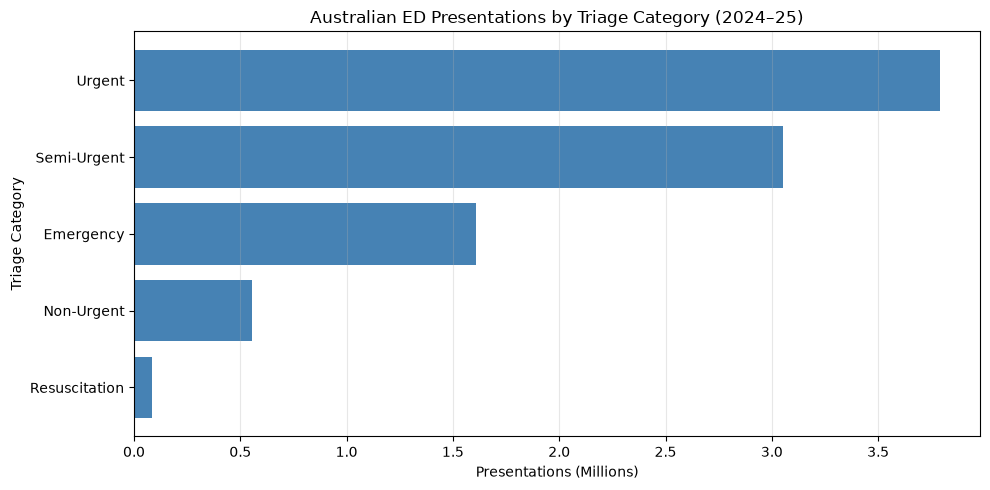

In [20]:
# Visualise presentation volumes by triage category
plt.figure(figsize=(10, 5))

plt.barh(
    triage_summary["Triage category"],
    triage_summary["Presentations_numeric"] / 1_000_000,
    color="steelblue"
)

plt.title("Australian ED Presentations by Triage Category (2024–25)")
plt.xlabel("Presentations (Millions)")
plt.ylabel("Triage Category")

# Display the highest-volume category at the top
plt.gca().invert_yaxis()

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

### Trends in Emergency Department Presentations by Triage Category

In [21]:
# Calculate annual presentations for each triage category
triage_trends = (
    national_data.groupby(["Year", "Triage category"])["Presentations_numeric"]
    .sum()
    .unstack()
)

# Display annual presentation trends
display(triage_trends)

Triage category,Emergency,Non-Urgent,Resuscitation,Semi-Urgent,Urgent
Year,,,,,
2011–12,647788.0,724396.0,42634.0,2923231.0,2200172.0
2012–13,714124.0,669604.0,45292.0,2971536.0,2310691.0
2013–14,785791.0,791763.0,46741.0,3100559.0,2464328.0
2014–15,843443.0,759209.0,49035.0,3130356.0,2578398.0
2015–16,899906.0,712021.0,52718.0,3110520.0,2686516.0
2016–17,970883.0,719148.0,56543.0,3153383.0,2851977.0
2017–18,1043705.0,705993.0,60642.0,3201449.0,3002488.0
2018–19,1136383.0,695831.0,64515.0,3275094.0,3176986.0
2019–20,1158156.0,731798.0,66532.0,3127982.0,3148837.0


### Annual Presentation Trends by Triage Category

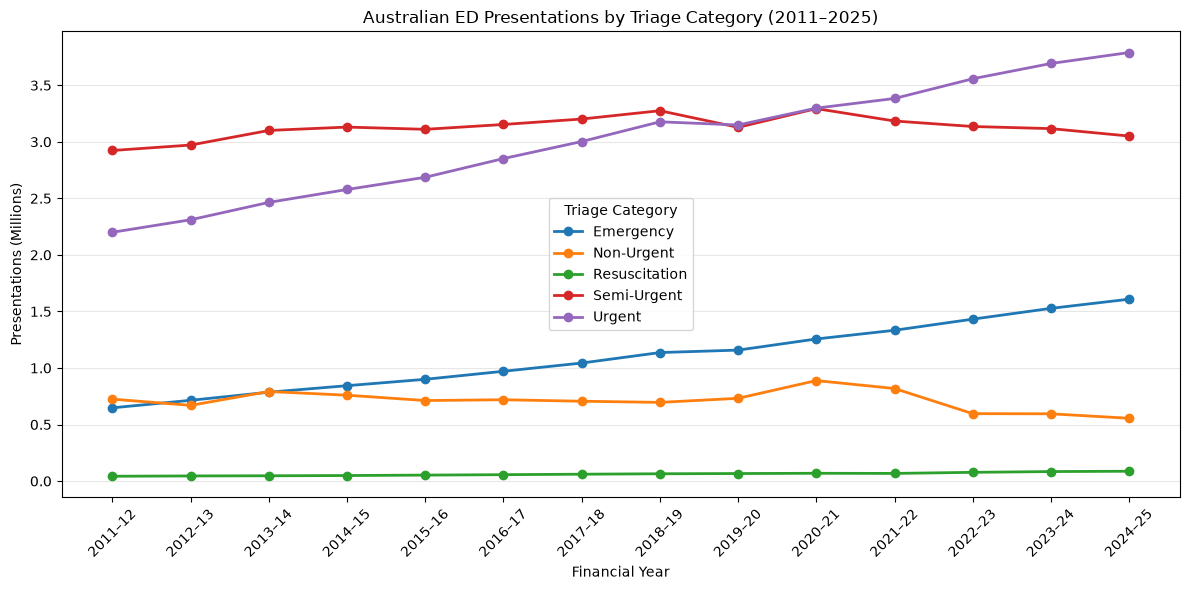

In [22]:
# Visualise annual presentation trends by triage category
plt.figure(figsize=(12, 6))

for category in triage_trends.columns:
    plt.plot(
        triage_trends.index,
        triage_trends[category] / 1_000_000,
        marker="o",
        linewidth=2,
        label=category
    )

plt.title("Australian ED Presentations by Triage Category (2011–2025)")
plt.xlabel("Financial Year")
plt.ylabel("Presentations (Millions)")

plt.xticks(rotation=45)
plt.legend(title="Triage Category")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

### Changes in Triage Category Distribution Over Time

In [23]:
# Calculate each triage category's percentage of annual presentations
triage_percentages = (
    triage_trends.div(triage_trends.sum(axis=1), axis=0) * 100
).round(2)

# Compare the first and latest reporting years
triage_comparison = triage_percentages.loc[
    ["2011–12", "2024–25"]
]

display(triage_comparison)

Triage category,Emergency,Non-Urgent,Resuscitation,Semi-Urgent,Urgent
Year,,,,,
2011–12,9.91,11.08,0.65,44.71,33.65
2024–25,17.69,6.11,0.96,33.56,41.69


### Percentage Distribution of Triage Categories Over Time

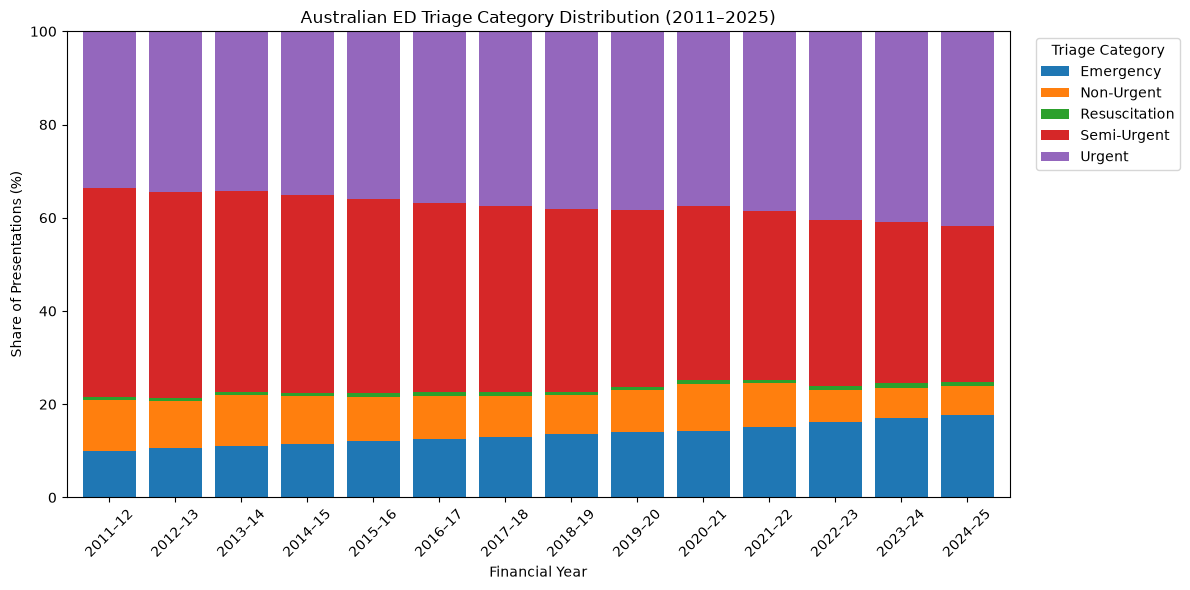

In [24]:
# Visualise annual triage category proportions
triage_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    width=0.8
)

plt.title("Australian ED Triage Category Distribution (2011–2025)")
plt.xlabel("Financial Year")
plt.ylabel("Share of Presentations (%)")

plt.legend(
    title="Triage Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Emergency Department Waiting-Time Performance

### Exploring the Patients Seen on Time Dataset

In [25]:
# Load the waiting-time worksheet without assigning column headers
waiting_time_raw = pd.read_excel(
    "../Data/myhosp-emergency-department-data-extract.xlsx",
    sheet_name="Patients seen on time",
    header=None
)

# Examine the worksheet structure
print("Dataset shape:", waiting_time_raw.shape)

display(waiting_time_raw.head(20))

Dataset shape: (21989, 11)


,0,1,2,3,4,5,6,7,8,9,10
0,NaN,"www.aihw.gov.au\nAustralian Institute of Health and Welfare\nGPO Box 570, Canberra ACT 2601, Aus...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Time spent in emergency departments,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Measure: Percentage of patients seen on time,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"Data as of: Wednesday, August 19, 2026, version: 2026081901",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Percentage of patients whose clinical care commenced within national benchmarks for waiting time...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Explanatory notes,NaN,NaN,NaN,NaN,"Triage 1. Resuscitation (requires immediate treatment, which was defined for this report as comm...",NaN,NaN,NaN,NaN,NaN
7,- There were no patients reported for this indicator in this time period.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NP Reported data did not meet the criteria to calculate this indicator.,NaN,NaN,NaN,NaN,Triage 2. Emergency (treatment required within 10 minutes),NaN,NaN,NaN,NaN,NaN
9,NP† Results could not be accurately calculated as more than 10% of presentations had missing or ...,NaN,NaN,NaN,NaN,Triage 3. Urgent (treatment required within 30 minutes),NaN,NaN,NaN,NaN,NaN


In [26]:
# Examine worksheet rows to locate the column headers
display(waiting_time_raw.iloc[10:25])

,0,1,2,3,4,5,6,7,8,9,10
10,* Interpret with caution: 5-10% of presentations had missing or invalid time data.,NaN,NaN,NaN,NaN,Triage 4. Semi-urgent (treatment required within 60 minutes),NaN,NaN,NaN,NaN,NaN
11,NaN,NaN,NaN,NaN,NaN,Triage 5. Non-urgent (treatment recommended within 120 minutes),NaN,NaN,NaN,NaN,NaN
12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13,"Excludes data for the Australian Capital Territory in 2015–16, which were not available for publ...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14,Additional data quality information can be found here.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
16,Reporting unit,Reporting unit type,State,Peer group,Year,Triage category,Number of presentations,NaN,Percentage of patients seen on time,NaN,Peer group average
17,National,National,NAT,NaN,2011–12,Emergency,644112,NaN,0.8,NaN,NaN
18,National,National,NAT,NaN,2012–13,Emergency,710966,NaN,0.82,NaN,NaN
19,National,National,NAT,NaN,2013–14,Emergency,781363,NaN,0.82,NaN,NaN


### Loading and Inspecting Waiting-Time Data

In [27]:
# Load waiting-time data using the correct header row
waiting_time = pd.read_excel(
    "../Data/myhosp-emergency-department-data-extract.xlsx",
    sheet_name="Patients seen on time",
    header=16
)

# Examine dataset dimensions and columns
print("Dataset shape:", waiting_time.shape)

print("\nColumn names:")
print(waiting_time.columns.tolist())

# Preview the first five records
display(waiting_time.head())

Dataset shape: (21972, 11)

Column names:
['Reporting unit', 'Reporting unit type', 'State', 'Peer group', 'Year', 'Triage category', 'Number of presentations', 'Unnamed: 7', 'Percentage of patients seen on time', 'Unnamed: 9', 'Peer group average']


,Reporting unit,Reporting unit type,State,Peer group,Year,Triage category,Number of presentations,Unnamed: 7,Percentage of patients seen on time,Unnamed: 9,Peer group average
0,National,National,NAT,NaN,2011–12,Emergency,644112,NaN,0.8,NaN,NaN
1,National,National,NAT,NaN,2012–13,Emergency,710966,NaN,0.82,NaN,NaN
2,National,National,NAT,NaN,2013–14,Emergency,781363,NaN,0.82,NaN,NaN
3,National,National,NAT,NaN,2014–15,Emergency,839117,NaN,0.79,NaN,NaN
4,National,National,NAT,NaN,2015–16,Emergency,895191,NaN,0.77,NaN,NaN


### Data Quality Assessment

In [28]:
# Examine column data types
print("Column data types:")
print(waiting_time.dtypes)

# Count missing values in each column
print("\nMissing values by column:")
print(waiting_time.isnull().sum())

Column data types:
Reporting unit                             str
Reporting unit type                        str
State                                      str
Peer group                                 str
Year                                       str
Triage category                            str
Number of presentations                 object
Unnamed: 7                             float64
Percentage of patients seen on time     object
Unnamed: 9                                 str
Peer group average                      object
dtype: object

Missing values by column:
Reporting unit                             0
Reporting unit type                        0
State                                      0
Peer group                              2700
Year                                       0
Triage category                            0
Number of presentations                    0
Unnamed: 7                             21972
Percentage of patients seen on time        0
Unnamed: 9        

### Investigating Non-Numeric Waiting-Time Values

In [29]:
# Identify non-numeric waiting-time performance values
waiting_numeric = pd.to_numeric(
    waiting_time["Percentage of patients seen on time"],
    errors="coerce"
)

# Extract records containing non-numeric values
waiting_non_numeric = waiting_time[
    waiting_numeric.isna()
]

# Display non-numeric value counts
print("Total records:", len(waiting_time))
print("Non-numeric records:", len(waiting_non_numeric))

print("\nUnique non-numeric values:")
print(
    waiting_non_numeric["Percentage of patients seen on time"]
    .value_counts(dropna=False)
)

Total records: 21972
Non-numeric records: 1203

Unique non-numeric values:
Percentage of patients seen on time
NP†    562
NP     495
-      146
Name: count, dtype: int64


In [30]:
# Display explanatory notes from the original worksheet
pd.set_option("display.max_colwidth", None)

display(
    waiting_time_raw.iloc[6:15, [0, 5]]
)

,0,5
6,Explanatory notes,"Triage 1. Resuscitation (requires immediate treatment, which was defined for this report as commencement of clinical care within 2 minutes from presentation time)"
7,- There were no patients reported for this indicator in this time period.,NaN
8,NP Reported data did not meet the criteria to calculate this indicator.,Triage 2. Emergency (treatment required within 10 minutes)
9,NP† Results could not be accurately calculated as more than 10% of presentations had missing or invalid time data.,Triage 3. Urgent (treatment required within 30 minutes)
10,* Interpret with caution: 5-10% of presentations had missing or invalid time data.,Triage 4. Semi-urgent (treatment required within 60 minutes)
11,NaN,Triage 5. Non-urgent (treatment recommended within 120 minutes)
12,NaN,NaN
13,"Excludes data for the Australian Capital Territory in 2015–16, which were not available for publication. At hospital and LHN level, these are also excluded for years prior to 2015–16.",NaN
14,Additional data quality information can be found here.,NaN


### Cleaning Waiting-Time Performance Values

In [31]:
# Preserve the original reporting values
waiting_time_clean = waiting_time.copy()

# Convert available waiting-time performance values to numeric
waiting_time_clean["Seen_on_time_numeric"] = pd.to_numeric(
    waiting_time_clean["Percentage of patients seen on time"],
    errors="coerce"
)

# Check numeric conversion results
print("Total records:", len(waiting_time_clean))
print(
    "Valid numeric records:",
    waiting_time_clean["Seen_on_time_numeric"].notna().sum()
)
print(
    "Unavailable performance records:",
    waiting_time_clean["Seen_on_time_numeric"].isna().sum()
)

# Preview the cleaned dataset
display(waiting_time_clean.head())

Total records: 21972
Valid numeric records: 20769
Unavailable performance records: 1203


,Reporting unit,Reporting unit type,State,Peer group,Year,Triage category,Number of presentations,Unnamed: 7,Percentage of patients seen on time,Unnamed: 9,Peer group average,Seen_on_time_numeric
0,National,National,NAT,NaN,2011–12,Emergency,644112,NaN,0.8,NaN,NaN,0.80
1,National,National,NAT,NaN,2012–13,Emergency,710966,NaN,0.82,NaN,NaN,0.82
2,National,National,NAT,NaN,2013–14,Emergency,781363,NaN,0.82,NaN,NaN,0.82
3,National,National,NAT,NaN,2014–15,Emergency,839117,NaN,0.79,NaN,NaN,0.79
4,National,National,NAT,NaN,2015–16,Emergency,895191,NaN,0.77,NaN,NaN,0.77


### Validating Waiting-Time Performance Values

In [32]:
# Check the minimum and maximum waiting-time proportions
print("Minimum value:", waiting_time_clean["Seen_on_time_numeric"].min())
print("Maximum value:", waiting_time_clean["Seen_on_time_numeric"].max())

# Identify numeric values outside the expected range
invalid_values = waiting_time_clean[
    waiting_time_clean["Seen_on_time_numeric"].notna()
    & ~waiting_time_clean["Seen_on_time_numeric"].between(0, 1)
]

print("Values outside 0–1 range:", len(invalid_values))

Minimum value: 0.09
Maximum value: 1.0
Values outside 0–1 range: 0


### Investigating Presentation Counts in Waiting-Time Data

In [33]:
# Identify non-numeric presentation counts
presentation_numeric = pd.to_numeric(
    waiting_time_clean["Number of presentations"],
    errors="coerce"
)

# Extract records containing non-numeric counts
non_numeric_counts = waiting_time_clean[
    presentation_numeric.isna()
]

# Display non-numeric reporting values
print("Total records:", len(waiting_time_clean))
print("Non-numeric presentation counts:", len(non_numeric_counts))

print("\nUnique non-numeric values:")
print(
    non_numeric_counts["Number of presentations"]
    .value_counts(dropna=False)
)

Total records: 21972
Non-numeric presentation counts: 329

Unique non-numeric values:
Number of presentations
<5    329
Name: count, dtype: int64


### Cleaning Presentation Counts in Waiting-Time Data

In [34]:
# Convert presentation counts to numeric values
waiting_time_clean["Presentations_numeric"] = pd.to_numeric(
    waiting_time_clean["Number of presentations"],
    errors="coerce"
)

# Verify numeric conversion
print("Total records:", len(waiting_time_clean))
print("Valid numeric counts:", waiting_time_clean["Presentations_numeric"].notna().sum())
print("Suppressed counts:", waiting_time_clean["Presentations_numeric"].isna().sum())

# Preview the updated dataset
display(waiting_time_clean.head())

Total records: 21972
Valid numeric counts: 21643
Suppressed counts: 329


,Reporting unit,Reporting unit type,State,Peer group,Year,Triage category,Number of presentations,Unnamed: 7,Percentage of patients seen on time,Unnamed: 9,Peer group average,Seen_on_time_numeric,Presentations_numeric
0,National,National,NAT,NaN,2011–12,Emergency,644112,NaN,0.8,NaN,NaN,0.80,644112.0
1,National,National,NAT,NaN,2012–13,Emergency,710966,NaN,0.82,NaN,NaN,0.82,710966.0
2,National,National,NAT,NaN,2013–14,Emergency,781363,NaN,0.82,NaN,NaN,0.82,781363.0
3,National,National,NAT,NaN,2014–15,Emergency,839117,NaN,0.79,NaN,NaN,0.79,839117.0
4,National,National,NAT,NaN,2015–16,Emergency,895191,NaN,0.77,NaN,NaN,0.77,895191.0


### Investigating Additional Data Quality Indicators

In [35]:
# Examine additional data quality indicators
print("Non-missing records:", waiting_time_clean["Unnamed: 9"].notna().sum())

print("\nUnique values:")
print(
    waiting_time_clean["Unnamed: 9"]
    .value_counts(dropna=False)
)

# Preview records containing data quality indicators
display(
    waiting_time_clean.loc[
        waiting_time_clean["Unnamed: 9"].notna(),
        [
            "Year",
            "Reporting unit",
            "Triage category",
            "Percentage of patients seen on time",
            "Unnamed: 9"
        ]
    ].head(10)
)

Non-missing records: 385

Unique values:
Unnamed: 9
NaN    21587
*        385
Name: count, dtype: int64


,Year,Reporting unit,Triage category,Percentage of patients seen on time,Unnamed: 9
155,2012–13,Armidale Hospital,Non-Urgent,0.93,*
158,2015–16,Armidale Hospital,Non-Urgent,0.94,*
159,2016–17,Armidale Hospital,Non-Urgent,0.94,*
160,2017–18,Armidale Hospital,Non-Urgent,0.93,*
174,2017–18,Armidale Hospital,Resuscitation,1,*
227,2014–15,Auburn Hospital,Non-Urgent,0.95,*
228,2015–16,Auburn Hospital,Non-Urgent,0.91,*
229,2016–17,Auburn Hospital,Non-Urgent,0.91,*
230,2017–18,Auburn Hospital,Non-Urgent,0.91,*
231,2018–19,Auburn Hospital,Non-Urgent,0.87,*


### Creating a Waiting-Time Data Quality Flag

In [36]:
# Create a flag for results requiring caution
waiting_time_clean["Data_quality_caution"] = (
    waiting_time_clean["Unnamed: 9"].eq("*")
)

# Verify the data quality flags
print("Records requiring caution:", waiting_time_clean["Data_quality_caution"].sum())

print(
    "Records without caution flag:",
    (~waiting_time_clean["Data_quality_caution"]).sum()
)

# Preview flagged records
display(
    waiting_time_clean.loc[
        waiting_time_clean["Data_quality_caution"],
        [
            "Reporting unit",
            "Year",
            "Triage category",
            "Seen_on_time_numeric",
            "Data_quality_caution"
        ]
    ].head()
)

Records requiring caution: 385
Records without caution flag: 21587


,Reporting unit,Year,Triage category,Seen_on_time_numeric,Data_quality_caution
155,Armidale Hospital,2012–13,Non-Urgent,0.93,True
158,Armidale Hospital,2015–16,Non-Urgent,0.94,True
159,Armidale Hospital,2016–17,Non-Urgent,0.94,True
160,Armidale Hospital,2017–18,Non-Urgent,0.93,True
174,Armidale Hospital,2017–18,Resuscitation,1.00,True


### Removing Unnecessary Columns

In [37]:
# Remove unnecessary worksheet columns
waiting_time_clean = waiting_time_clean.drop(
    columns=["Unnamed: 7", "Unnamed: 9"]
)

# Verify the updated dataset structure
print("Dataset shape:", waiting_time_clean.shape)

print("\nRemaining columns:")
print(waiting_time_clean.columns.tolist())

# Preview the updated dataset
display(waiting_time_clean.head())

Dataset shape: (21972, 12)

Remaining columns:
['Reporting unit', 'Reporting unit type', 'State', 'Peer group', 'Year', 'Triage category', 'Number of presentations', 'Percentage of patients seen on time', 'Peer group average', 'Seen_on_time_numeric', 'Presentations_numeric', 'Data_quality_caution']


,Reporting unit,Reporting unit type,State,Peer group,Year,Triage category,Number of presentations,Percentage of patients seen on time,Peer group average,Seen_on_time_numeric,Presentations_numeric,Data_quality_caution
0,National,National,NAT,NaN,2011–12,Emergency,644112,0.8,NaN,0.80,644112.0,False
1,National,National,NAT,NaN,2012–13,Emergency,710966,0.82,NaN,0.82,710966.0,False
2,National,National,NAT,NaN,2013–14,Emergency,781363,0.82,NaN,0.82,781363.0,False
3,National,National,NAT,NaN,2014–15,Emergency,839117,0.79,NaN,0.79,839117.0,False
4,National,National,NAT,NaN,2015–16,Emergency,895191,0.77,NaN,0.77,895191.0,False


### Investigating Peer Group Average Values

In [38]:
# Convert peer group averages to numeric values temporarily
peer_numeric = pd.to_numeric(
    waiting_time_clean["Peer group average"],
    errors="coerce"
)

# Identify non-numeric reporting values
peer_non_numeric = waiting_time_clean.loc[
    waiting_time_clean["Peer group average"].notna()
    & peer_numeric.isna(),
    "Peer group average"
]

# Examine peer group average data quality
print("Total records:", len(waiting_time_clean))
print("Valid numeric averages:", peer_numeric.notna().sum())
print("Missing peer group averages:", waiting_time_clean["Peer group average"].isna().sum())
print("Non-numeric reporting codes:", len(peer_non_numeric))

print("\nUnique non-numeric values:")
print(peer_non_numeric.value_counts())

Total records: 21972
Valid numeric averages: 14420
Missing peer group averages: 2700
Non-numeric reporting codes: 4852

Unique non-numeric values:
Peer group average
Not peered    4852
Name: count, dtype: int64


### Cleaning Peer Group Average Values

In [39]:
# Convert available peer group averages to numeric values
waiting_time_clean["Peer_group_average_numeric"] = pd.to_numeric(
    waiting_time_clean["Peer group average"],
    errors="coerce"
)

# Verify numeric conversion
print("Total records:", len(waiting_time_clean))
print("Valid numeric averages:", waiting_time_clean["Peer_group_average_numeric"].notna().sum())
print("Unavailable averages:", waiting_time_clean["Peer_group_average_numeric"].isna().sum())

# Check the numeric range
print("Minimum average:", waiting_time_clean["Peer_group_average_numeric"].min())
print("Maximum average:", waiting_time_clean["Peer_group_average_numeric"].max())

Total records: 21972
Valid numeric averages: 14420
Unavailable averages: 7552
Minimum average: 0.51
Maximum average: 1.0


### Checking Duplicate Waiting-Time Records

In [40]:
# Identify duplicate records using reporting unit, year and triage category
duplicate_records = waiting_time_clean.duplicated(
    subset=[
        "Reporting unit type",
        "Reporting unit",
        "State",
        "Year",
        "Triage category"
    ],
    keep=False
)

# Display duplicate record counts
print("Total records:", len(waiting_time_clean))
print("Duplicate records:", duplicate_records.sum())

# Preview duplicate records if any exist
if duplicate_records.sum() > 0:
    display(waiting_time_clean[duplicate_records].head(10))

Total records: 21972
Duplicate records: 0


## National Emergency Department Waiting-Time Performance

### National Data Completeness

In [41]:
# Filter national-level waiting-time records
national_waiting = waiting_time_clean[
    waiting_time_clean["Reporting unit type"] == "National"
].copy()

# Examine national data completeness
print("Total national records:", len(national_waiting))
print("Reporting years:", national_waiting["Year"].nunique())
print("Triage categories:", national_waiting["Triage category"].nunique())
print("Unavailable performance values:", national_waiting["Seen_on_time_numeric"].isna().sum())
print("Records requiring caution:", national_waiting["Data_quality_caution"].sum())

# Display national waiting-time records
display(national_waiting.head())

Total national records: 70
Reporting years: 14
Triage categories: 5
Unavailable performance values: 0
Records requiring caution: 0


,Reporting unit,Reporting unit type,State,Peer group,Year,Triage category,Number of presentations,Percentage of patients seen on time,Peer group average,Seen_on_time_numeric,Presentations_numeric,Data_quality_caution,Peer_group_average_numeric
0,National,National,NAT,NaN,2011–12,Emergency,644112,0.8,NaN,0.80,644112.0,False,NaN
1,National,National,NAT,NaN,2012–13,Emergency,710966,0.82,NaN,0.82,710966.0,False,NaN
2,National,National,NAT,NaN,2013–14,Emergency,781363,0.82,NaN,0.82,781363.0,False,NaN
3,National,National,NAT,NaN,2014–15,Emergency,839117,0.79,NaN,0.79,839117.0,False,NaN
4,National,National,NAT,NaN,2015–16,Emergency,895191,0.77,NaN,0.77,895191.0,False,NaN


In [42]:
# Summarise national waiting-time data completeness
print("Total national records:", len(national_waiting))
print("Reporting years:", national_waiting["Year"].nunique())
print("Triage categories:", national_waiting["Triage category"].nunique())
print("Unavailable performance values:", national_waiting["Seen_on_time_numeric"].isna().sum())
print("Records requiring caution:", national_waiting["Data_quality_caution"].sum())

Total national records: 70
Reporting years: 14
Triage categories: 5
Unavailable performance values: 0
Records requiring caution: 0


### National Waiting-Time Performance Trends by Triage Category

In [43]:
# Organise national waiting-time performance by year and triage category
waiting_trends = national_waiting.pivot(
    index="Year",
    columns="Triage category",
    values="Seen_on_time_numeric"
)

# Convert proportions into percentages
waiting_trends = (waiting_trends * 100).round(2)

# Display annual waiting-time performance
display(waiting_trends)

Triage category,Emergency,Non-Urgent,Resuscitation,Semi-Urgent,Urgent
Year,,,,,
2011–12,80.0,89.0,100.0,70.0,66.0
2012–13,82.0,91.0,100.0,72.0,68.0
2013–14,82.0,92.0,100.0,75.0,70.0
2014–15,79.0,92.0,100.0,74.0,68.0
2015–16,77.0,93.0,100.0,74.0,67.0
2016–17,77.0,92.0,100.0,74.0,66.0
2017–18,76.0,92.0,100.0,73.0,64.0
2018–19,75.0,91.0,100.0,73.0,63.0
2019–20,75.0,93.0,100.0,76.0,67.0


### National On-Time Treatment Rates by Triage Category

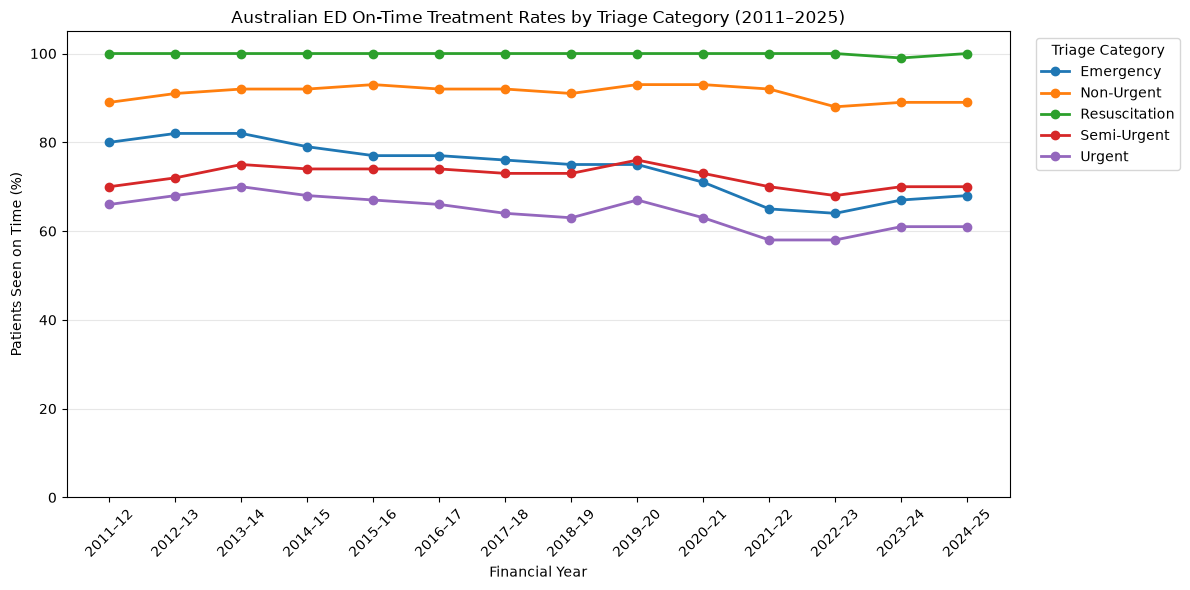

In [44]:
# Visualise national on-time treatment rates by triage category
plt.figure(figsize=(12, 6))

for category in waiting_trends.columns:
    plt.plot(
        waiting_trends.index,
        waiting_trends[category],
        marker="o",
        linewidth=2,
        label=category
    )

plt.title("Australian ED On-Time Treatment Rates by Triage Category (2011–2025)")
plt.xlabel("Financial Year")
plt.ylabel("Patients Seen on Time (%)")

plt.ylim(0, 105)
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.legend(
    title="Triage Category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### Emergency Triage Demand and On-Time Performance Comparison

In [45]:
# Extract national Emergency presentation volumes
emergency_demand = triage_trends["Emergency"].rename(
    "Presentations"
)

# Extract national Emergency on-time treatment rates
emergency_performance = waiting_trends["Emergency"].rename(
    "Seen_on_time_pct"
)

# Combine demand and performance by financial year
emergency_comparison = pd.concat(
    [emergency_demand, emergency_performance],
    axis=1
)

# Display the comparison
display(emergency_comparison)

,Presentations,Seen_on_time_pct
Year,,
2011–12,647788.0,80.0
2012–13,714124.0,82.0
2013–14,785791.0,82.0
2014–15,843443.0,79.0
2015–16,899906.0,77.0
2016–17,970883.0,77.0
2017–18,1043705.0,76.0
2018–19,1136383.0,75.0
2019–20,1158156.0,75.0


### Emergency Presentation Demand vs On-Time Treatment Performance

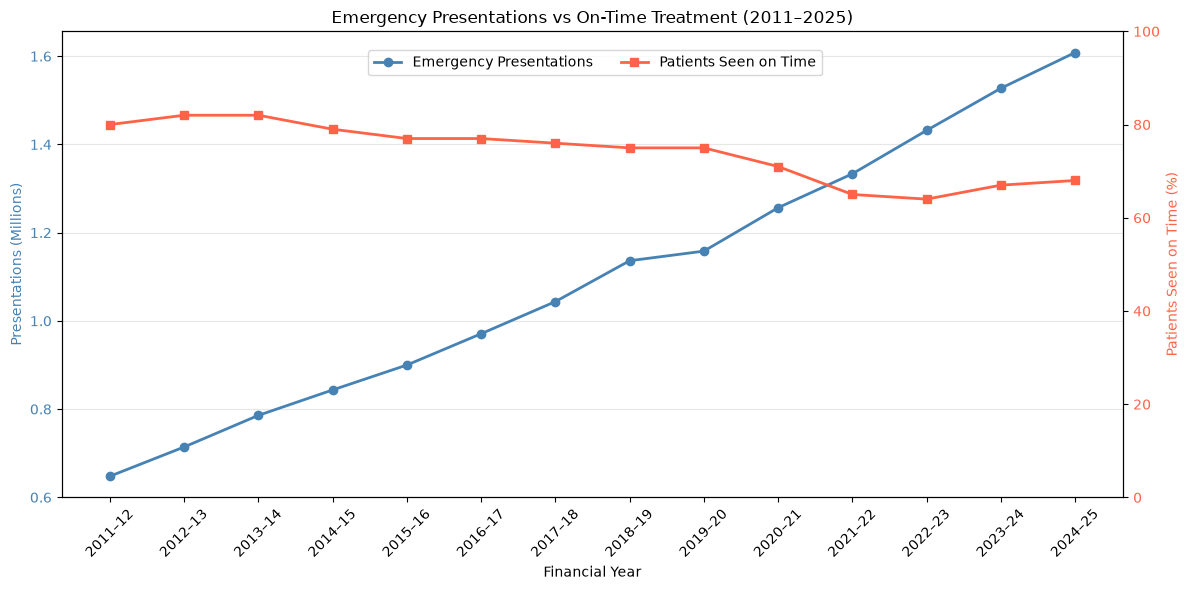

In [46]:
# Create a chart comparing Emergency demand and on-time performance
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Emergency presentation volumes
ax1.plot(
    emergency_comparison.index,
    emergency_comparison["Presentations"] / 1_000_000,
    color="steelblue",
    marker="o",
    linewidth=2,
    label="Emergency Presentations"
)

ax1.set_xlabel("Financial Year")
ax1.set_ylabel("Presentations (Millions)", color="steelblue")
ax1.tick_params(axis="y", labelcolor="steelblue")

# Plot on-time treatment performance on a secondary axis
ax2 = ax1.twinx()

ax2.plot(
    emergency_comparison.index,
    emergency_comparison["Seen_on_time_pct"],
    color="tomato",
    marker="s",
    linewidth=2,
    label="Patients Seen on Time"
)

ax2.set_ylabel("Patients Seen on Time (%)", color="tomato")
ax2.tick_params(axis="y", labelcolor="tomato")
ax2.set_ylim(0, 100)

# Format the chart
plt.title("Emergency Presentations vs On-Time Treatment (2011–2025)")
ax1.tick_params(axis="x", rotation=45)
ax1.grid(axis="y", alpha=0.3)

fig.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 0.92),
    ncol=2
)

plt.tight_layout()
plt.show()

### Correlation Between Emergency Demand and On-Time Treatment Performance

In [47]:
# Calculate the Pearson correlation between demand and performance
correlation = emergency_comparison[
    ["Presentations", "Seen_on_time_pct"]
].corr(method="pearson")

# Display the correlation matrix
display(correlation)

# Extract the correlation coefficient
correlation_value = correlation.loc[
    "Presentations", "Seen_on_time_pct"
]

print("Pearson correlation coefficient:", round(correlation_value, 3))

,Presentations,Seen_on_time_pct
Presentations,1.000000,-0.926327
Seen_on_time_pct,-0.926327,1.000000


Pearson correlation coefficient: -0.926


### Year-over-Year Changes in Emergency Demand and Performance

In [48]:
# Calculate annual percentage growth in Emergency presentations
emergency_comparison["Demand_growth_pct"] = (
    emergency_comparison["Presentations"].pct_change() * 100
)

# Calculate annual percentage-point changes in on-time performance
emergency_comparison["Performance_change_pp"] = (
    emergency_comparison["Seen_on_time_pct"].diff()
)

# Display annual changes
display(
    emergency_comparison[
        ["Demand_growth_pct", "Performance_change_pp"]
    ].round(2)
)

,Demand_growth_pct,Performance_change_pp
Year,,
2011–12,NaN,NaN
2012–13,10.24,2.0
2013–14,10.04,0.0
2014–15,7.34,-3.0
2015–16,6.69,-2.0
2016–17,7.89,0.0
2017–18,7.50,-1.0
2018–19,8.88,-1.0
2019–20,1.92,0.0


### Correlation Between Annual Demand Growth and Performance Changes

In [49]:
# Select annual demand growth and performance changes
annual_changes = emergency_comparison[
    ["Demand_growth_pct", "Performance_change_pp"]
].dropna()

# Calculate the Pearson correlation between annual changes
annual_change_correlation = annual_changes[
    "Demand_growth_pct"
].corr(
    annual_changes["Performance_change_pp"]
)

# Display results
print("Number of annual comparisons:", len(annual_changes))
print(
    "Correlation between annual changes:",
    round(annual_change_correlation, 3)
)

Number of annual comparisons: 13
Correlation between annual changes: 0.05


### Relationship Between Annual Demand Growth and Waiting-Time Performance Changes

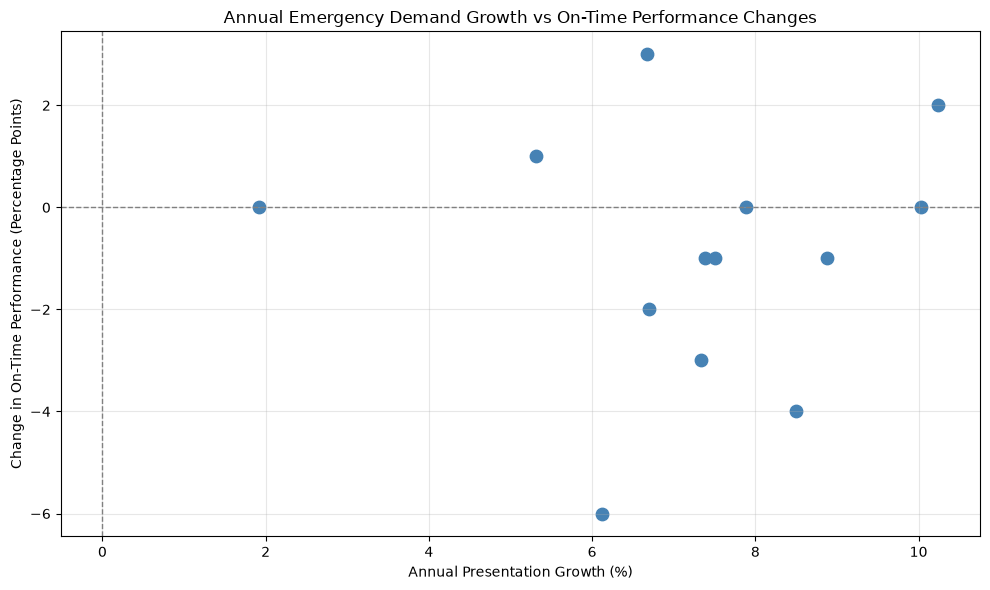

In [50]:
# Visualise annual demand growth against changes in on-time performance
plt.figure(figsize=(10, 6))

plt.scatter(
    annual_changes["Demand_growth_pct"],
    annual_changes["Performance_change_pp"],
    color="steelblue",
    s=80
)

plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.axvline(0, color="gray", linestyle="--", linewidth=1)

plt.title("Annual Emergency Demand Growth vs On-Time Performance Changes")
plt.xlabel("Annual Presentation Growth (%)")
plt.ylabel("Change in On-Time Performance (Percentage Points)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## State-Level Emergency Department Performance Analysis

### State-Level Data Completeness

In [51]:
# Filter state-level waiting-time records
state_waiting = waiting_time_clean[
    waiting_time_clean["Reporting unit type"] == "State"
].copy()

# Examine state-level data completeness
print("Total state-level records:", len(state_waiting))
print("States and territories:", state_waiting["State"].nunique())
print("Reporting years:", state_waiting["Year"].nunique())
print("Triage categories:", state_waiting["Triage category"].nunique())

print(
    "Unavailable performance values:",
    state_waiting["Seen_on_time_numeric"].isna().sum()
)

print(
    "Records requiring caution:",
    state_waiting["Data_quality_caution"].sum()
)

# Display records by state or territory
print("\nRecords by state or territory:")
print(state_waiting["State"].value_counts())

Total state-level records: 555
States and territories: 8
Reporting years: 14
Triage categories: 5
Unavailable performance values: 2
Records requiring caution: 14

Records by state or territory:
State
NSW    70
Vic    70
Qld    70
SA     70
WA     70
Tas    70
NT     70
ACT    65
Name: count, dtype: int64


### Investigating State-Level Reporting Gaps

In [52]:
# Identify available ACT records by financial year
act_data = state_waiting[
    state_waiting["State"] == "ACT"
]

# Count reported triage categories in each year
act_yearly_counts = (
    act_data.groupby("Year")["Triage category"]
    .nunique()
    .reindex(sorted(state_waiting["Year"].unique()), fill_value=0)
)

# Display ACT reporting completeness
print("ACT triage records by financial year:")
display(act_yearly_counts.to_frame("Triage_categories_reported"))

ACT triage records by financial year:


,Triage_categories_reported
Year,
2011–12,5
2012–13,5
2013–14,5
2014–15,5
2015–16,0
2016–17,5
2017–18,5
2018–19,5
2019–20,5


### Investigating Unavailable State-Level Performance Values

In [53]:
# Identify state-level records with unavailable performance values
state_unavailable = state_waiting[
    state_waiting["Seen_on_time_numeric"].isna()
]

# Display the affected states, years and reporting codes
display(
    state_unavailable[
        [
            "State",
            "Year",
            "Triage category",
            "Percentage of patients seen on time",
            "Number of presentations"
        ]
    ]
)

,State,Year,Triage category,Percentage of patients seen on time,Number of presentations
18813,SA,2013–14,Semi-Urgent,NP†,181761
18814,SA,2014–15,Semi-Urgent,NP†,178718


### Investigating State-Level Data Quality Caution Flags

In [54]:
# Identify state-level records requiring cautious interpretation
state_caution = state_waiting[
    state_waiting["Data_quality_caution"]
].copy()

# Display affected records
print("Records requiring caution:", len(state_caution))

display(
    state_caution[
        [
            "State",
            "Year",
            "Triage category",
            "Seen_on_time_numeric",
            "Presentations_numeric"
        ]
    ]
)

Records requiring caution: 14


,State,Year,Triage category,Seen_on_time_numeric,Presentations_numeric
7600,NSW,2011–12,Non-Urgent,0.89,264998.0
7601,NSW,2012–13,Non-Urgent,0.92,234972.0
7602,NSW,2013–14,Non-Urgent,0.94,295767.0
7603,NSW,2014–15,Non-Urgent,0.95,282218.0
7604,NSW,2015–16,Non-Urgent,0.94,272563.0
18771,SA,2013–14,Emergency,0.74,59306.0
18772,SA,2014–15,Emergency,0.69,62756.0
18785,SA,2013–14,Non-Urgent,0.92,31589.0
18786,SA,2014–15,Non-Urgent,0.89,30588.0
18827,SA,2013–14,Urgent,0.65,165939.0


### State-Level Urgent Treatment Performance (2024–25)

In [55]:

# Filter state-level Urgent presentations for the latest financial year
urgent_state_2024 = state_waiting[
    (state_waiting["Year"] == "2024–25")
    & (state_waiting["Triage category"] == "Urgent")
].copy()

# Convert on-time proportions into percentages
urgent_state_2024["On_time_pct"] = (
    urgent_state_2024["Seen_on_time_numeric"] * 100
)

# Sort states by on-time treatment performance
urgent_state_2024 = urgent_state_2024.sort_values(
    "On_time_pct",
    ascending=False
)

# Display state-level performance
display(
    urgent_state_2024[
        ["State", "On_time_pct", "Presentations_numeric", "Data_quality_caution"]
    ]
)


,State,On_time_pct,Presentations_numeric,Data_quality_caution
14794,Vic,69.0,830969.0,False
7655,NSW,68.0,1164979.0,False
16898,Qld,67.0,802932.0,False
21881,ACT,51.0,71405.0,False
18838,SA,44.0,243454.0,False
21571,NT,40.0,57693.0,False
21236,Tas,38.0,76296.0,False
20886,WA,29.0,367450.0,False


### Comparison of Urgent Treatment Performance Across States (2024–25)

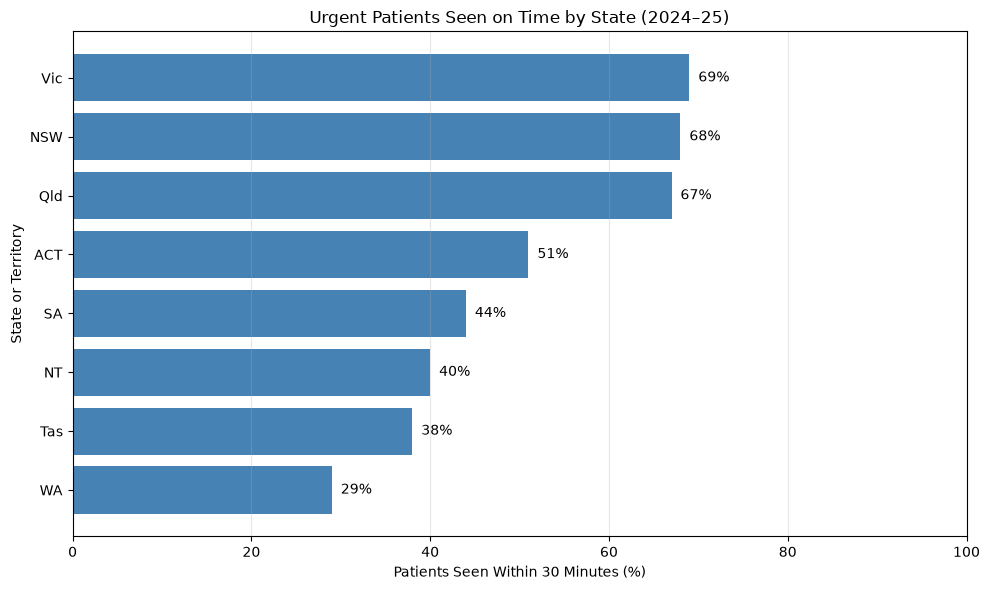

In [56]:
# Visualise state-level Urgent treatment performance
plt.figure(figsize=(10, 6))

plt.barh(
    urgent_state_2024["State"],
    urgent_state_2024["On_time_pct"],
    color="steelblue"
)

# Display the highest-performing state at the top
plt.gca().invert_yaxis()

plt.title("Urgent Patients Seen on Time by State (2024–25)")
plt.xlabel("Patients Seen Within 30 Minutes (%)")
plt.ylabel("State or Territory")

plt.xlim(0, 100)
plt.grid(axis="x", alpha=0.3)

# Display percentages at the end of each bar
for i, value in enumerate(urgent_state_2024["On_time_pct"]):
    plt.text(value + 1, i, f"{value:.0f}%", va="center")

plt.tight_layout()
plt.show()

### State-Level Waiting-Time Performance by Triage Category (2024–25)

In [57]:
# Filter state-level waiting-time performance for 2024–25
state_performance_2024 = state_waiting[
    state_waiting["Year"] == "2024–25"
].copy()

# Create a comparison table by state and triage category
state_triage_comparison = state_performance_2024.pivot(
    index="State",
    columns="Triage category",
    values="Seen_on_time_numeric"
)

# Convert proportions into percentages
state_triage_comparison = (
    state_triage_comparison * 100
).round(2)

# Arrange states by Urgent treatment performance
state_triage_comparison = state_triage_comparison.sort_values(
    "Urgent",
    ascending=False
)

display(state_triage_comparison)

Triage category,Emergency,Non-Urgent,Resuscitation,Semi-Urgent,Urgent
State,,,,,
Vic,64.0,91.0,100.0,76.0,69.0
NSW,76.0,90.0,100.0,74.0,68.0
Qld,73.0,93.0,100.0,78.0,67.0
ACT,64.0,89.0,99.0,69.0,51.0
SA,50.0,84.0,99.0,61.0,44.0
NT,49.0,82.0,98.0,48.0,40.0
Tas,47.0,74.0,100.0,52.0,38.0
WA,67.0,80.0,100.0,47.0,29.0


### State-Level On-Time Treatment Performance Heatmap (2024–25)

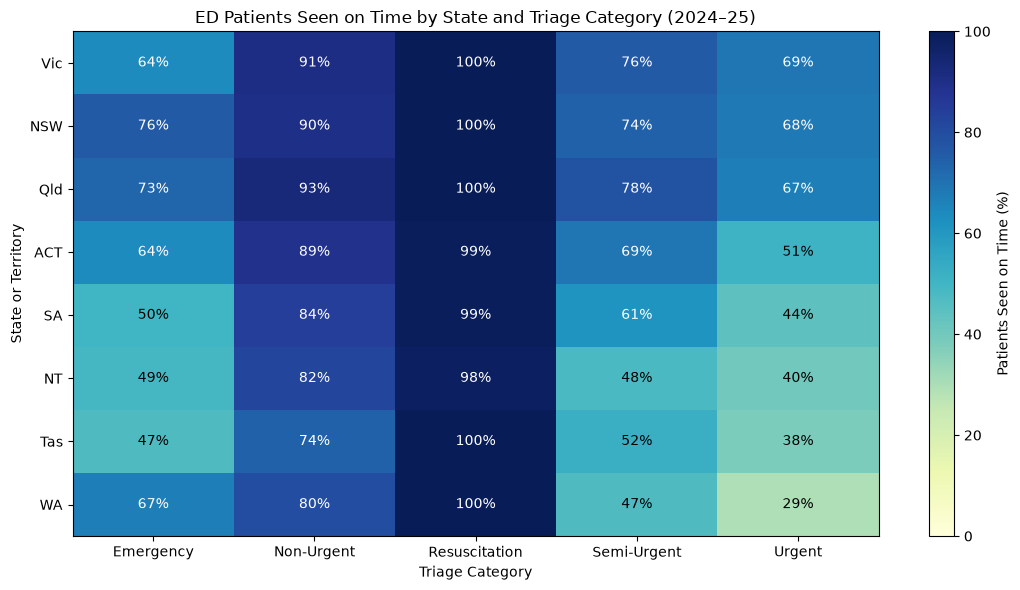

In [58]:
# Prepare state-level performance data for visualisation
fig, ax = plt.subplots(figsize=(11, 6))

heatmap = ax.imshow(
    state_triage_comparison,
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    aspect="auto"
)

# Configure state and triage category labels
ax.set_xticks(range(len(state_triage_comparison.columns)))
ax.set_xticklabels(state_triage_comparison.columns)

ax.set_yticks(range(len(state_triage_comparison.index)))
ax.set_yticklabels(state_triage_comparison.index)

# Display percentage values inside each cell
for i in range(len(state_triage_comparison.index)):
    for j in range(len(state_triage_comparison.columns)):
        value = state_triage_comparison.iloc[i, j]
        ax.text(
            j, i, f"{value:.0f}%",
            ha="center",
            va="center",
            color="white" if value >= 60 else "black"
        )

# Add title and colour scale
ax.set_title("ED Patients Seen on Time by State and Triage Category (2024–25)")
ax.set_xlabel("Triage Category")
ax.set_ylabel("State or Territory")

fig.colorbar(heatmap, ax=ax, label="Patients Seen on Time (%)")

plt.tight_layout()
plt.show()

### Historical Trends in Urgent Treatment Performance by State

In [59]:
# Select state-level Urgent treatment performance
urgent_state_trends = state_waiting[
    state_waiting["Triage category"] == "Urgent"
].copy()

# Organise performance by financial year and state
urgent_trends_table = urgent_state_trends.pivot(
    index="Year",
    columns="State",
    values="Seen_on_time_numeric"
)

# Convert proportions into percentages
urgent_trends_table = (
    urgent_trends_table * 100
).round(2)

# Display historical performance
display(urgent_trends_table)

State,ACT,NSW,NT,Qld,SA,Tas,Vic,WA
Year,,,,,,,,
2011–12,50.0,71.0,49.0,63.0,70.0,64.0,72.0,52.0
2012–13,43.0,73.0,52.0,68.0,66.0,65.0,72.0,52.0
2013–14,50.0,76.0,51.0,67.0,65.0,66.0,73.0,58.0
2014–15,48.0,76.0,54.0,64.0,57.0,64.0,73.0,57.0
2015–16,NaN,76.0,53.0,61.0,56.0,59.0,71.0,53.0
2016–17,50.0,76.0,55.0,60.0,52.0,57.0,70.0,50.0
2017–18,37.0,76.0,49.0,59.0,48.0,56.0,68.0,50.0
2018–19,32.0,74.0,54.0,61.0,46.0,56.0,66.0,48.0
2019–20,34.0,76.0,60.0,71.0,55.0,58.0,65.0,52.0


### Historical Urgent Treatment Performance Across Australian States

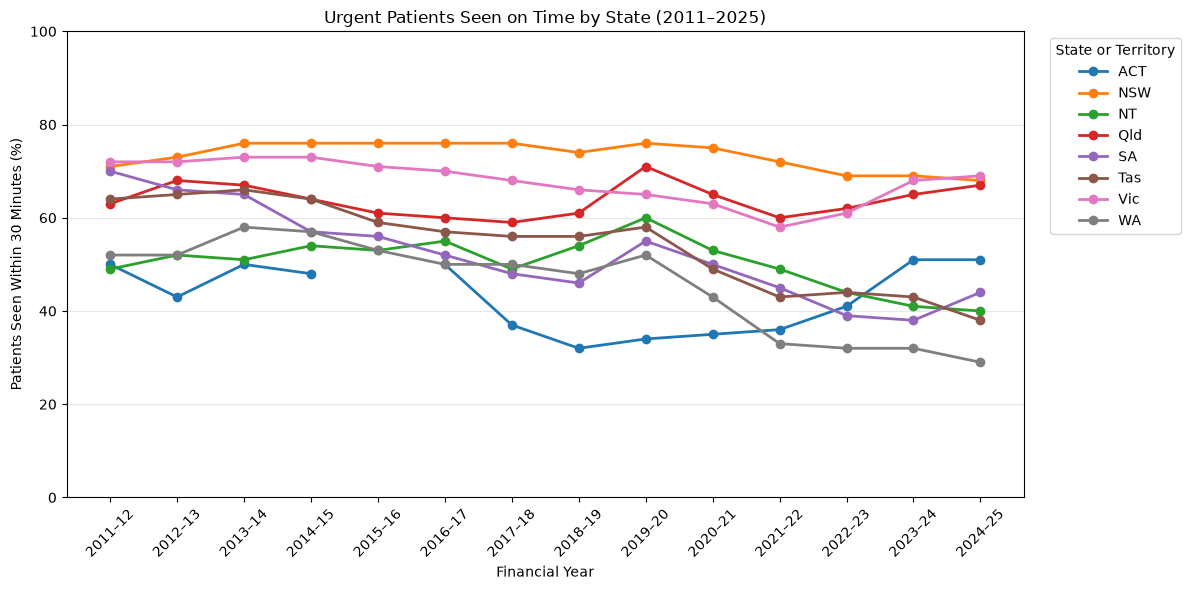

In [60]:
# Visualise historical Urgent treatment performance by state
plt.figure(figsize=(12, 6))

for state in urgent_trends_table.columns:
    plt.plot(
        urgent_trends_table.index,
        urgent_trends_table[state],
        marker="o",
        linewidth=2,
        label=state
    )

plt.title("Urgent Patients Seen on Time by State (2011–2025)")
plt.xlabel("Financial Year")
plt.ylabel("Patients Seen Within 30 Minutes (%)")

plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.legend(
    title="State or Territory",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### Changes in Urgent Treatment Performance by State (2011–12 to 2024–25)

In [61]:
# Compare Urgent treatment performance between the first and latest years
state_performance_change = pd.DataFrame({
    "2011–12": urgent_trends_table.loc["2011–12"],
    "2024–25": urgent_trends_table.loc["2024–25"]
})

# Calculate changes in percentage points
state_performance_change["Change_pp"] = (
    state_performance_change["2024–25"]
    - state_performance_change["2011–12"]
)

# Sort by change in treatment performance
state_performance_change = state_performance_change.sort_values(
    "Change_pp",
    ascending=False
)

display(state_performance_change)

,2011–12,2024–25,Change_pp
State,,,
Qld,63.0,67.0,4.0
ACT,50.0,51.0,1.0
NSW,71.0,68.0,-3.0
Vic,72.0,69.0,-3.0
NT,49.0,40.0,-9.0
WA,52.0,29.0,-23.0
Tas,64.0,38.0,-26.0
SA,70.0,44.0,-26.0


## Hospital-Level Emergency Department Performance Analysis

### Hospital Data Completeness

In [62]:
# Filter individual hospital waiting-time records
hospital_waiting = waiting_time_clean[
    waiting_time_clean["Reporting unit type"] == "Hospital"
].copy()

# Examine hospital-level data completeness
print("Total hospital records:", len(hospital_waiting))
print("Unique hospitals:", hospital_waiting["Reporting unit"].nunique())
print("Reporting years:", hospital_waiting["Year"].nunique())
print("Triage categories:", hospital_waiting["Triage category"].nunique())

print(
    "Unavailable performance values:",
    hospital_waiting["Seen_on_time_numeric"].isna().sum()
)

print(
    "Records requiring caution:",
    hospital_waiting["Data_quality_caution"].sum()
)

print(
    "Suppressed presentation counts:",
    hospital_waiting["Presentations_numeric"].isna().sum()
)

Total hospital records: 18717
Unique hospitals: 311
Reporting years: 14
Triage categories: 5
Unavailable performance values: 1191
Records requiring caution: 369
Suppressed presentation counts: 329


### Hospital Reporting Coverage Across Financial Years

In [63]:
# Count reporting years available for each hospital
hospital_coverage = (
    hospital_waiting.groupby(["State", "Reporting unit"])["Year"]
    .nunique()
    .reset_index(name="Years_reported")
)

# Examine hospital reporting coverage
print("Hospital reporting coverage:")
print(hospital_coverage["Years_reported"].value_counts().sort_index())

print("\nHospitals with all 14 reporting years:",
      (hospital_coverage["Years_reported"] == 14).sum())

print("Hospitals with fewer than 14 reporting years:",
      (hospital_coverage["Years_reported"] < 14).sum())

# Preview hospitals with limited reporting coverage
display(
    hospital_coverage[
        hospital_coverage["Years_reported"] < 14
    ].sort_values("Years_reported").head(10)
)

Hospital reporting coverage:
Years_reported
1       1
2       1
3       1
4       8
5       1
6       6
7      11
8       6
9       4
10      4
11      5
12     77
13      2
14    184
Name: count, dtype: int64

Hospitals with all 14 reporting years: 184
Hospitals with fewer than 14 reporting years: 127


,State,Reporting unit,Years_reported
178,NSW,White Cliffs Health Service,1
0,ACT,North Canberra Hospital,2
276,Vic,Victorian Heart Hospital,3
24,NSW,Bonalbo Hospital,4
118,NSW,Mullumbimby Hospital,4
205,Qld,Mater Children's Hospital,4
33,NSW,Byron Bay Hospital,4
64,NSW,Eugowra Memorial Multipurpose Service,4
216,Qld,Royal Children's Hospital [Queensland],4
292,WA,Fremantle Hospital and Health Service,4


### Valid Hospital Waiting-Time Performance Coverage

In [64]:
# Select hospital records with available waiting-time performance
hospital_valid = hospital_waiting[
    hospital_waiting["Seen_on_time_numeric"].notna()
]

# Count years with valid performance results for each hospital
valid_coverage = (
    hospital_valid.groupby(["State", "Reporting unit"])["Year"]
    .nunique()
    .reset_index(name="Years_with_valid_performance")
)

# Include hospitals with no valid performance records
hospital_coverage_valid = hospital_coverage.merge(
    valid_coverage,
    on=["State", "Reporting unit"],
    how="left"
)

hospital_coverage_valid["Years_with_valid_performance"] = (
    hospital_coverage_valid["Years_with_valid_performance"]
    .fillna(0)
    .astype(int)
)

# Summarise performance data availability
print(
    "Hospitals with 14 years of valid performance:",
    (hospital_coverage_valid["Years_with_valid_performance"] == 14).sum()
)

print(
    "Hospitals with fewer than 14 years of valid performance:",
    (hospital_coverage_valid["Years_with_valid_performance"] < 14).sum()
)

print(
    "\nDistribution of years with valid performance:"
)
print(
    hospital_coverage_valid["Years_with_valid_performance"]
    .value_counts()
    .sort_index()
)

Hospitals with 14 years of valid performance: 180
Hospitals with fewer than 14 years of valid performance: 131

Distribution of years with valid performance:
Years_with_valid_performance
1       3
2       2
3       1
4       7
5       1
6       6
7      11
8       7
9       5
10     10
11     24
12     52
13      2
14    180
Name: count, dtype: int64


### Hospital Performance Completeness by Triage Category (2024–25)

In [65]:
# Select hospital performance records for 2024–25
hospital_2024 = hospital_waiting[
    hospital_waiting["Year"] == "2024–25"
].copy()

# Count valid triage category results for each hospital
hospital_triage_coverage = (
    hospital_2024[
        hospital_2024["Seen_on_time_numeric"].notna()
    ]
    .groupby(["State", "Reporting unit"])["Triage category"]
    .nunique()
    .reset_index(name="Valid_triage_categories")
)

# Include hospitals without any valid triage results
hospital_triage_coverage = (
    hospital_2024[["State", "Reporting unit"]]
    .drop_duplicates()
    .merge(
        hospital_triage_coverage,
        on=["State", "Reporting unit"],
        how="left"
    )
)

hospital_triage_coverage["Valid_triage_categories"] = (
    hospital_triage_coverage["Valid_triage_categories"]
    .fillna(0)
    .astype(int)
)

# Summarise hospital performance completeness
print("Hospitals reporting in 2024–25:", len(hospital_triage_coverage))

print("\nValid triage categories per hospital:")
print(
    hospital_triage_coverage["Valid_triage_categories"]
    .value_counts()
    .sort_index()
)

Hospitals reporting in 2024–25: 291

Valid triage categories per hospital:
Valid_triage_categories
1      1
2      1
3      3
4     79
5    207
Name: count, dtype: int64


### Hospital Peer Group Classification (2024–25)

In [66]:
# Examine hospital peer group classifications
print("Hospital peer groups:")

print(
    hospital_2024["Peer group"]
    .value_counts(dropna=False)
)

# Count unique hospitals in each peer group
print("\nUnique hospitals by peer group:")

display(
    hospital_2024.groupby(
        "Peer group",
        dropna=False
    )["Reporting unit"].nunique()
)

Hospital peer groups:
Peer group
Unpeered                         341
Small hospitals                  314
Major hospitals                  155
Large regional hospitals         150
Large metropolitan hospitals     150
Medium regional hospitals        115
Medium metropolitan hospitals    108
Children's hospitals              30
Name: count, dtype: int64

Unique hospitals by peer group:


Peer group
Children's hospitals              6
Large metropolitan hospitals     30
Large regional hospitals         30
Major hospitals                  31
Medium metropolitan hospitals    22
Medium regional hospitals        23
Small hospitals                  65
Unpeered                         84
Name: Reporting unit, dtype: int64

### Peer Group Benchmark Availability for Urgent Patients (2024–25)

In [67]:
# Select hospital-level Urgent performance for 2024–25
hospital_urgent_2024 = hospital_2024[
    hospital_2024["Triage category"] == "Urgent"
].copy()

# Check hospital performance and peer benchmark availability
print("Total hospital records:", len(hospital_urgent_2024))

print(
    "Valid hospital performance values:",
    hospital_urgent_2024["Seen_on_time_numeric"].notna().sum()
)

print(
    "Available peer group benchmarks:",
    hospital_urgent_2024["Peer_group_average_numeric"].notna().sum()
)

print(
    "Records with both values available:",
    (
        hospital_urgent_2024["Seen_on_time_numeric"].notna()
        & hospital_urgent_2024["Peer_group_average_numeric"].notna()
    ).sum()
)

print(
    "Records requiring caution:",
    hospital_urgent_2024["Data_quality_caution"].sum()
)

Total hospital records: 290
Valid hospital performance values: 290
Available peer group benchmarks: 207
Records with both values available: 207
Records requiring caution: 0


### Hospital Urgent Treatment Performance vs Peer Group Benchmarks (2024–25)

In [68]:
# Select hospitals with valid performance and peer group benchmarks
hospital_peer_comparison = hospital_urgent_2024[
    hospital_urgent_2024["Seen_on_time_numeric"].notna()
    & hospital_urgent_2024["Peer_group_average_numeric"].notna()
].copy()

# Convert hospital and peer group performance into percentages
hospital_peer_comparison["Hospital_on_time_pct"] = (
    hospital_peer_comparison["Seen_on_time_numeric"] * 100
)

hospital_peer_comparison["Peer_average_pct"] = (
    hospital_peer_comparison["Peer_group_average_numeric"] * 100
)

# Calculate the difference from the peer group benchmark
hospital_peer_comparison["Difference_pp"] = (
    hospital_peer_comparison["Hospital_on_time_pct"]
    - hospital_peer_comparison["Peer_average_pct"]
).round(2)

# Display comparison results
display(
    hospital_peer_comparison[
        [
            "Reporting unit",
            "State",
            "Peer group",
            "Hospital_on_time_pct",
            "Peer_average_pct",
            "Difference_pp"
        ]
    ].head(10)
)

,Reporting unit,State,Peer group,Hospital_on_time_pct,Peer_average_pct,Difference_pp
139,Albury Wodonga Health [Albury Campus],NSW,Large regional hospitals,55.0,58.0,-3.0
209,Armidale Hospital,NSW,Medium regional hospitals,72.0,64.0,8.0
278,Auburn Hospital,NSW,Medium metropolitan hospitals,81.0,72.0,9.0
348,Ballina District Hospital,NSW,Small hospitals,61.0,71.0,-10.0
472,Bankstown Lidcombe Hospital,NSW,Large metropolitan hospitals,70.0,56.0,14.0
714,Batemans Bay Hospital,NSW,Small hospitals,82.0,71.0,11.0
784,Bathurst Base Hospital,NSW,Large regional hospitals,72.0,58.0,14.0
892,Bellinger River District Hospital,NSW,Small hospitals,98.0,71.0,27.0
962,Belmont Hospital,NSW,Medium metropolitan hospitals,87.0,72.0,15.0
1149,Blacktown Hospital,NSW,Large metropolitan hospitals,42.0,56.0,-14.0


### Assessing Hospital Presentation Volumes for Benchmarking

In [69]:
# Examine presentation volumes for hospitals with peer benchmarks
print("Hospitals with peer benchmarks:", len(hospital_peer_comparison))

print(
    "Missing presentation counts:",
    hospital_peer_comparison["Presentations_numeric"].isna().sum()
)

print("\nPresentation volume statistics:")
display(
    hospital_peer_comparison["Presentations_numeric"]
    .describe()
    .round(2)
)

Hospitals with peer benchmarks: 207
Missing presentation counts: 0

Presentation volume statistics:


count      207.00
mean     17159.89
std      13648.19
min        415.00
25%       5358.00
50%      13102.00
75%      26724.00
max      57315.00
Name: Presentations_numeric, dtype: float64

### Distribution of Hospital Performance Against Peer Benchmarks

In [70]:
# Categorise hospitals based on peer benchmark differences
hospital_peer_comparison["Benchmark_status"] = (
    hospital_peer_comparison["Difference_pp"].apply(
        lambda value: "Above benchmark" if value > 0
        else "Below benchmark" if value < 0
        else "Equal to benchmark"
    )
)

# Count hospitals in each benchmark category
print("Hospital performance relative to peer benchmarks:")
print(hospital_peer_comparison["Benchmark_status"].value_counts())

# Summarise performance differences
print("\nPerformance difference statistics (percentage points):")
display(
    hospital_peer_comparison["Difference_pp"]
    .describe()
    .round(2)
)

Hospital performance relative to peer benchmarks:
Benchmark_status
Above benchmark       138
Below benchmark        62
Equal to benchmark      7
Name: count, dtype: int64

Performance difference statistics (percentage points):


count    207.00
mean       2.37
std       17.33
min      -49.00
25%       -4.50
50%        6.00
75%       13.50
max       40.00
Name: Difference_pp, dtype: float64

### Hospitals With the Largest Differences From Peer Benchmarks

In [71]:
# Select useful hospital benchmarking information
comparison_columns = [
    "Reporting unit",
    "State",
    "Peer group",
    "Presentations_numeric",
    "Hospital_on_time_pct",
    "Peer_average_pct",
    "Difference_pp"
]

# Identify hospitals furthest above their peer benchmarks
print("Largest positive benchmark differences:")
display(
    hospital_peer_comparison.nlargest(
        10, "Difference_pp"
    )[comparison_columns]
)

# Identify hospitals furthest below their peer benchmarks
print("\nLargest negative benchmark differences:")
display(
    hospital_peer_comparison.nsmallest(
        10, "Difference_pp"
    )[comparison_columns]
)

Largest positive benchmark differences:


,Reporting unit,State,Peer group,Presentations_numeric,Hospital_on_time_pct,Peer_average_pct,Difference_pp
12527,Dandenong Hospital,Vic,Large metropolitan hospitals,35589.0,96.0,56.0,40.0
13372,Monash Medical Centre [Clayton],Vic,Major hospitals,50725.0,89.0,58.0,31.0
1981,Calvary Mater Newcastle,NSW,Large metropolitan hospitals,12560.0,85.0,56.0,29.0
2669,Concord Repatriation Hospital,NSW,Major hospitals,22249.0,87.0,58.0,29.0
3386,Deniliquin Hospital,NSW,Small hospitals,2635.0,100.0,71.0,29.0
12737,Frankston Hospital,Vic,Large metropolitan hospitals,34402.0,84.0,56.0,28.0
13032,Maroondah Hospital [East Ringwood],Vic,Large metropolitan hospitals,22795.0,84.0,56.0,28.0
892,Bellinger River District Hospital,NSW,Small hospitals,942.0,98.0,71.0,27.0
1581,Bowral Hospital,NSW,Medium regional hospitals,9511.0,91.0,64.0,27.0
7426,Narrandera Hospital,NSW,Small hospitals,1361.0,98.0,71.0,27.0



Largest negative benchmark differences:


,Reporting unit,State,Peer group,Presentations_numeric,Hospital_on_time_pct,Peer_average_pct,Difference_pp
20386,Peel Health Campus,WA,Medium regional hospitals,15682.0,15.0,64.0,-49.0
19733,Fiona Stanley Hospital,WA,Major hospitals,39399.0,11.0,58.0,-47.0
20756,St John of God Midland Public Hospital,WA,Large metropolitan hospitals,28973.0,9.0,56.0,-47.0
21621,Palmerston Regional Hospital,NT,Small hospitals,9241.0,24.0,71.0,-47.0
19962,Joondalup Health Campus (Public),WA,Large metropolitan hospitals,38267.0,10.0,56.0,-46.0
20531,Rockingham General Hospital,WA,Large metropolitan hospitals,23429.0,13.0,56.0,-43.0
14878,Werribee Mercy Hospital,Vic,Medium metropolitan hospitals,23034.0,30.0,72.0,-42.0
19313,Armadale-Kelmscott Memorial Hospital,WA,Large metropolitan hospitals,27066.0,14.0,56.0,-42.0
20601,Royal Perth Hospital Wellington Street Campus,WA,Major hospitals,29597.0,17.0,58.0,-41.0
21691,Royal Darwin Hospital,NT,Major hospitals,22184.0,18.0,58.0,-40.0


### Hospitals With the Largest Urgent Treatment Benchmark Differences (2024–25)

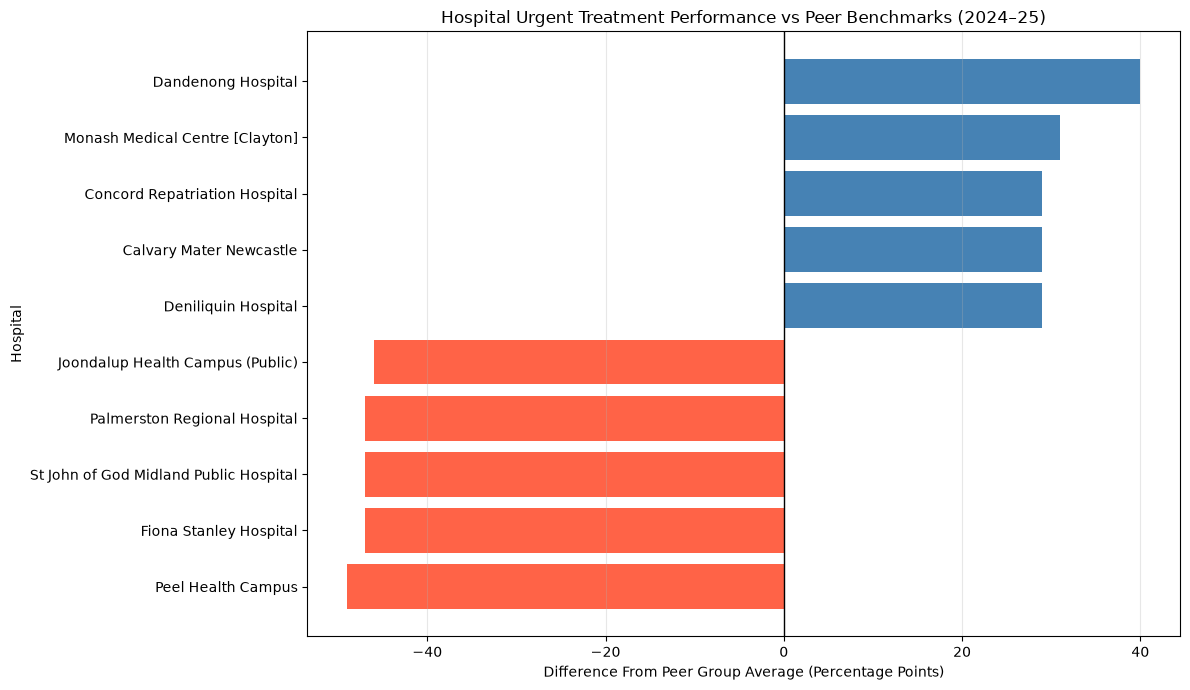

In [72]:
# Select hospitals with the largest positive and negative benchmark differences
top_hospitals = hospital_peer_comparison.nlargest(5, "Difference_pp")
bottom_hospitals = hospital_peer_comparison.nsmallest(5, "Difference_pp")

benchmark_outliers = pd.concat([top_hospitals, bottom_hospitals])

# Sort hospitals by their difference from the peer benchmark
benchmark_outliers = benchmark_outliers.sort_values("Difference_pp")

# Visualise differences from peer group averages
plt.figure(figsize=(12, 7))

plt.barh(
    benchmark_outliers["Reporting unit"],
    benchmark_outliers["Difference_pp"],
    color=[
        "steelblue" if value >= 0 else "tomato"
        for value in benchmark_outliers["Difference_pp"]
    ]
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Hospital Urgent Treatment Performance vs Peer Benchmarks (2024–25)")
plt.xlabel("Difference From Peer Group Average (Percentage Points)")
plt.ylabel("Hospital")

plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

## Emergency Department Four-Hour Performance Analysis

### Exploring the Four-Hour Performance Dataset

In [73]:
# Load the four-hour emergency department performance worksheet
four_hour_raw = pd.read_excel(
    "../Data/myhosp-emergency-department-data-extract.xlsx",
    sheet_name="Time in ED - within 4 hrs",
    header=None
)

# Examine worksheet structure
print("Dataset shape:", four_hour_raw.shape)

# Preview worksheet headings and metadata
display(four_hour_raw.head(20))

Dataset shape: (36309, 11)


,0,1,2,3,4,5,6,7,8,9,10
0,NaN,"www.aihw.gov.au\nAustralian Institute of Health and Welfare\nGPO Box 570, Canberra ACT 2601, Australia",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Time spent in emergency departments,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Measure: Percentage of patients who depart the emergency department within four hours of arrival,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"Data as of: Wednesday, August 19, 2026, version: 2026081901",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"The percentage of patients who departed the emergency department (ED) within four hours of arrival. \nData are presented for all patients, for patients admitted from the emergency department to the same hospital, for patients discharged from the emergency department, and by triage category (the urgency of the patient's need for care as assessed by an emergency department healthcare professional). \nThe five triage categories are: Resuscitation, Emergency, Urgent, Semi-urgent and Non-urgent. \n\nNote: The measure includes presentations with any type of visit code (not just emergency presentations).",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Explanatory notes,NaN,NaN,NaN,NaN,Admitted patients (Admitted from the emergency department to the same hospital),NaN,NaN,NaN,NaN,NaN
7,- There were no patients reported for this indicator in this time period.,NaN,NaN,NaN,NaN,"Discharged patients (Discharged from emergency department, left at their own risk or referred to another hospital)",NaN,NaN,NaN,NaN,NaN
8,NP Reported data did not meet the criteria to calculate this indicator.,NaN,NaN,NaN,NaN,"Triage 1. Resuscitation (requires immediate treatment, which was defined for this report as commencement of clinical care within 2 minutes from presentation time)",NaN,NaN,NaN,NaN,NaN
9,NP† Results could not be accurately calculated as more than 10% of presentations had missing or invalid time data.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Loading and Inspecting Four-Hour Performance Data

In [74]:
# Load four-hour emergency department performance data
four_hour = pd.read_excel(
    "../Data/myhosp-emergency-department-data-extract.xlsx",
    sheet_name="Time in ED - within 4 hrs",
    header=19
)

# Examine dataset dimensions
print("Dataset shape:", four_hour.shape)

# Display column names
print("\nColumn names:")
print(four_hour.columns.tolist())

# Preview the first five records
display(four_hour.head())

Dataset shape: (36289, 11)

Column names:
['Reporting unit', 'Reporting unit type', 'State', 'Peer group', 'Year', 'Patient cohort', 'Number of presentations', 'Unnamed: 7', 'Percentage who depart ED within 4 hrs', 'Unnamed: 9', 'Peer group average']


,Reporting unit,Reporting unit type,State,Peer group,Year,Patient cohort,Number of presentations,Unnamed: 7,Percentage who depart ED within 4 hrs,Unnamed: 9,Peer group average
0,National,National,NAT,NaN,2011–12,All patients,6547342,NaN,0.64,NaN,NaN
1,National,National,NAT,NaN,2012–13,All patients,6717067,NaN,0.67,NaN,NaN
2,National,National,NAT,NaN,2013–14,All patients,7195903,NaN,0.73,NaN,NaN
3,National,National,NAT,NaN,2014–15,All patients,7366442,NaN,0.73,NaN,NaN
4,National,National,NAT,NaN,2015–16,All patients,7465869,NaN,0.73,NaN,NaN


### Exploring Patient Cohort Categories

In [75]:
# Identify patient cohort categories
print("Patient cohort categories:")
print(four_hour["Patient cohort"].value_counts(dropna=False))

# Examine patient cohorts at the national level
print("\nNational-level patient cohorts:")
print(
    four_hour[
        four_hour["Reporting unit type"] == "National"
    ]["Patient cohort"].value_counts(dropna=False)
)

Patient cohort categories:
Patient cohort
All patients                          4537
Emergency                             4537
Non-Urgent                            4537
Not subsequently admitted patients    4537
Semi-Urgent                           4537
Subsequently admitted patients        4537
Urgent                                4537
Resuscitation                         4530
Name: count, dtype: int64

National-level patient cohorts:
Patient cohort
All patients                          14
Emergency                             14
Non-Urgent                            14
Not subsequently admitted patients    14
Resuscitation                         14
Semi-Urgent                           14
Subsequently admitted patients        14
Urgent                                14
Name: count, dtype: int64


### Four-Hour Performance Data Quality Assessment

In [76]:
# Examine column data types
print("Column data types:")
print(four_hour.dtypes)

# Identify missing values in each column
print("\nMissing values by column:")
print(four_hour.isnull().sum())

Column data types:
Reporting unit                               str
Reporting unit type                          str
State                                        str
Peer group                                   str
Year                                         str
Patient cohort                               str
Number of presentations                   object
Unnamed: 7                               float64
Percentage who depart ED within 4 hrs     object
Unnamed: 9                                   str
Peer group average                        object
dtype: object

Missing values by column:
Reporting unit                               0
Reporting unit type                          0
State                                        0
Peer group                                4401
Year                                         0
Patient cohort                               0
Number of presentations                      0
Unnamed: 7                               36289
Percentage who depart ED 

### Investigating Non-Numeric Four-Hour Performance Values

In [77]:
# Identify non-numeric four-hour performance values
four_hour_numeric = pd.to_numeric(
    four_hour["Percentage who depart ED within 4 hrs"],
    errors="coerce"
)

# Extract records containing non-numeric values
four_hour_non_numeric = four_hour[
    four_hour_numeric.isna()
]

# Display non-numeric reporting values
print("Total records:", len(four_hour))
print("Valid numeric records:", four_hour_numeric.notna().sum())
print("Non-numeric records:", len(four_hour_non_numeric))

print("\nUnique non-numeric values:")
print(
    four_hour_non_numeric["Percentage who depart ED within 4 hrs"]
    .value_counts(dropna=False)
)

Total records: 36289
Valid numeric records: 34660
Non-numeric records: 1629

Unique non-numeric values:
Percentage who depart ED within 4 hrs
NP     1067
-       373
NP†     189
Name: count, dtype: int64


### Cleaning Four-Hour Performance Values

In [78]:
# Create a working copy of the four-hour performance dataset
four_hour_clean = four_hour.copy()

# Convert available performance proportions to numeric values
four_hour_clean["Within_4hrs_numeric"] = pd.to_numeric(
    four_hour_clean["Percentage who depart ED within 4 hrs"],
    errors="coerce"
)

# Verify numeric conversion
print("Total records:", len(four_hour_clean))
print("Valid numeric records:", four_hour_clean["Within_4hrs_numeric"].notna().sum())
print("Unavailable performance records:", four_hour_clean["Within_4hrs_numeric"].isna().sum())

# Check the numeric range
print("Minimum value:", four_hour_clean["Within_4hrs_numeric"].min())
print("Maximum value:", four_hour_clean["Within_4hrs_numeric"].max())

# Preview the updated dataset
display(four_hour_clean.head())

Total records: 36289
Valid numeric records: 34660
Unavailable performance records: 1629
Minimum value: 0.02
Maximum value: 1.0


,Reporting unit,Reporting unit type,State,Peer group,Year,Patient cohort,Number of presentations,Unnamed: 7,Percentage who depart ED within 4 hrs,Unnamed: 9,Peer group average,Within_4hrs_numeric
0,National,National,NAT,NaN,2011–12,All patients,6547342,NaN,0.64,NaN,NaN,0.64
1,National,National,NAT,NaN,2012–13,All patients,6717067,NaN,0.67,NaN,NaN,0.67
2,National,National,NAT,NaN,2013–14,All patients,7195903,NaN,0.73,NaN,NaN,0.73
3,National,National,NAT,NaN,2014–15,All patients,7366442,NaN,0.73,NaN,NaN,0.73
4,National,National,NAT,NaN,2015–16,All patients,7465869,NaN,0.73,NaN,NaN,0.73


### Investigating Presentation Counts in Four-Hour Performance Data

In [79]:
# Identify non-numeric presentation counts
four_hour_counts = pd.to_numeric(
    four_hour_clean["Number of presentations"],
    errors="coerce"
)

# Extract records containing non-numeric values
non_numeric_counts = four_hour_clean[
    four_hour_counts.isna()
]

# Display reporting code frequencies
print("Total records:", len(four_hour_clean))
print("Valid numeric counts:", four_hour_counts.notna().sum())
print("Non-numeric counts:", len(non_numeric_counts))

print("\nUnique non-numeric values:")
print(
    non_numeric_counts["Number of presentations"]
    .value_counts(dropna=False)
)

Total records: 36289
Valid numeric counts: 35636
Non-numeric counts: 653

Unique non-numeric values:
Number of presentations
<5    653
Name: count, dtype: int64


### Cleaning Presentation Counts in Four-Hour Performance Data

In [80]:
# Convert presentation counts to numeric values
four_hour_clean["Presentations_numeric"] = pd.to_numeric(
    four_hour_clean["Number of presentations"],
    errors="coerce"
)

# Verify numeric conversion
print("Total records:", len(four_hour_clean))
print("Valid numeric counts:", four_hour_clean["Presentations_numeric"].notna().sum())
print("Suppressed counts:", four_hour_clean["Presentations_numeric"].isna().sum())

# Preview the updated dataset
display(four_hour_clean.head())

Total records: 36289
Valid numeric counts: 35636
Suppressed counts: 653


,Reporting unit,Reporting unit type,State,Peer group,Year,Patient cohort,Number of presentations,Unnamed: 7,Percentage who depart ED within 4 hrs,Unnamed: 9,Peer group average,Within_4hrs_numeric,Presentations_numeric
0,National,National,NAT,NaN,2011–12,All patients,6547342,NaN,0.64,NaN,NaN,0.64,6547342.0
1,National,National,NAT,NaN,2012–13,All patients,6717067,NaN,0.67,NaN,NaN,0.67,6717067.0
2,National,National,NAT,NaN,2013–14,All patients,7195903,NaN,0.73,NaN,NaN,0.73,7195903.0
3,National,National,NAT,NaN,2014–15,All patients,7366442,NaN,0.73,NaN,NaN,0.73,7366442.0
4,National,National,NAT,NaN,2015–16,All patients,7465869,NaN,0.73,NaN,NaN,0.73,7465869.0


### Investigating Four-Hour Performance Data Quality Indicators

In [81]:
# Examine additional data quality indicators
print("Non-missing records:", four_hour_clean["Unnamed: 9"].notna().sum())

print("\nUnique values:")
print(
    four_hour_clean["Unnamed: 9"]
    .value_counts(dropna=False)
)

# Preview records containing data quality indicators
display(
    four_hour_clean.loc[
        four_hour_clean["Unnamed: 9"].notna(),
        [
            "Reporting unit",
            "Year",
            "Patient cohort",
            "Percentage who depart ED within 4 hrs",
            "Unnamed: 9"
        ]
    ].head(10)
)

Non-missing records: 306

Unique values:
Unnamed: 9
NaN    35983
*        306
Name: count, dtype: int64


,Reporting unit,Year,Patient cohort,Percentage who depart ED within 4 hrs,Unnamed: 9
622,Balranald Multi Purpose Service,2015–16,Semi-Urgent,0.96,*
634,Balranald Multi Purpose Service,2015–16,Subsequently admitted patients,0.98,*
645,Balranald Multi Purpose Service,2014–15,Urgent,0.93,*
646,Balranald Multi Purpose Service,2015–16,Urgent,0.95,*
961,Barraba Multi Purpose Service,2012–13,All patients,0.98,*
962,Barraba Multi Purpose Service,2013–14,All patients,0.99,*
963,Barraba Multi Purpose Service,2014–15,All patients,0.98,*
975,Barraba Multi Purpose Service,2012–13,Emergency,0.91,*
990,Barraba Multi Purpose Service,2013–14,Non-Urgent,1,*
991,Barraba Multi Purpose Service,2014–15,Non-Urgent,1,*


### Creating a Four-Hour Performance Data Quality Flag

In [82]:
# Create a flag for results requiring cautious interpretation
four_hour_clean["Data_quality_caution"] = (
    four_hour_clean["Unnamed: 9"].eq("*")
)

# Verify the data quality flags
print("Records requiring caution:", four_hour_clean["Data_quality_caution"].sum())

print(
    "Records without caution flag:",
    (~four_hour_clean["Data_quality_caution"]).sum()
)

# Preview flagged records
display(
    four_hour_clean.loc[
        four_hour_clean["Data_quality_caution"],
        [
            "Reporting unit",
            "Year",
            "Patient cohort",
            "Within_4hrs_numeric",
            "Data_quality_caution"
        ]
    ].head()
)

Records requiring caution: 306
Records without caution flag: 35983


,Reporting unit,Year,Patient cohort,Within_4hrs_numeric,Data_quality_caution
622,Balranald Multi Purpose Service,2015–16,Semi-Urgent,0.96,True
634,Balranald Multi Purpose Service,2015–16,Subsequently admitted patients,0.98,True
645,Balranald Multi Purpose Service,2014–15,Urgent,0.93,True
646,Balranald Multi Purpose Service,2015–16,Urgent,0.95,True
961,Barraba Multi Purpose Service,2012–13,All patients,0.98,True


### Removing Unnecessary Columns

In [83]:
# Remove unnecessary worksheet columns
four_hour_clean = four_hour_clean.drop(
    columns=["Unnamed: 7", "Unnamed: 9"]
)

# Verify the updated dataset structure
print("Dataset shape:", four_hour_clean.shape)

print("\nRemaining columns:")
print(four_hour_clean.columns.tolist())

# Preview the updated dataset
display(four_hour_clean.head())

Dataset shape: (36289, 12)

Remaining columns:
['Reporting unit', 'Reporting unit type', 'State', 'Peer group', 'Year', 'Patient cohort', 'Number of presentations', 'Percentage who depart ED within 4 hrs', 'Peer group average', 'Within_4hrs_numeric', 'Presentations_numeric', 'Data_quality_caution']


,Reporting unit,Reporting unit type,State,Peer group,Year,Patient cohort,Number of presentations,Percentage who depart ED within 4 hrs,Peer group average,Within_4hrs_numeric,Presentations_numeric,Data_quality_caution
0,National,National,NAT,NaN,2011–12,All patients,6547342,0.64,NaN,0.64,6547342.0,False
1,National,National,NAT,NaN,2012–13,All patients,6717067,0.67,NaN,0.67,6717067.0,False
2,National,National,NAT,NaN,2013–14,All patients,7195903,0.73,NaN,0.73,7195903.0,False
3,National,National,NAT,NaN,2014–15,All patients,7366442,0.73,NaN,0.73,7366442.0,False
4,National,National,NAT,NaN,2015–16,All patients,7465869,0.73,NaN,0.73,7465869.0,False


### Investigating Four-Hour Peer Group Average Values

In [84]:
# Convert peer group averages to numeric values temporarily
peer_numeric = pd.to_numeric(
    four_hour_clean["Peer group average"],
    errors="coerce"
)

# Identify non-numeric reporting values
peer_non_numeric = four_hour_clean.loc[
    four_hour_clean["Peer group average"].notna()
    & peer_numeric.isna(),
    "Peer group average"
]

# Examine peer group average data quality
print("Total records:", len(four_hour_clean))
print("Valid numeric averages:", peer_numeric.notna().sum())
print("Missing peer group averages:", four_hour_clean["Peer group average"].isna().sum())
print("Non-numeric reporting codes:", len(peer_non_numeric))

print("\nUnique non-numeric values:")
print(peer_non_numeric.value_counts())

Total records: 36289
Valid numeric averages: 23200
Missing peer group averages: 4401
Non-numeric reporting codes: 8688

Unique non-numeric values:
Peer group average
Not peered    8688
Name: count, dtype: int64


### Cleaning Four-Hour Peer Group Average Values

In [85]:
# Convert available peer group averages to numeric values
four_hour_clean["Peer_group_average_numeric"] = pd.to_numeric(
    four_hour_clean["Peer group average"],
    errors="coerce"
)

# Verify numeric conversion
print("Total records:", len(four_hour_clean))
print("Valid numeric averages:", four_hour_clean["Peer_group_average_numeric"].notna().sum())
print("Unavailable averages:", four_hour_clean["Peer_group_average_numeric"].isna().sum())

# Check the numeric range
print("Minimum average:", four_hour_clean["Peer_group_average_numeric"].min())
print("Maximum average:", four_hour_clean["Peer_group_average_numeric"].max())

Total records: 36289
Valid numeric averages: 23200
Unavailable averages: 13089
Minimum average: 0.24
Maximum average: 0.97


### Checking Duplicate Four-Hour Performance Records

In [86]:
# Identify duplicate records using reporting unit, year and patient cohort
duplicate_records = four_hour_clean.duplicated(
    subset=[
        "Reporting unit type",
        "Reporting unit",
        "State",
        "Year",
        "Patient cohort"
    ],
    keep=False
)

# Display duplicate record counts
print("Total records:", len(four_hour_clean))
print("Duplicate records:", duplicate_records.sum())

# Preview duplicate records if any exist
if duplicate_records.sum() > 0:
    display(four_hour_clean[duplicate_records].head(10))

Total records: 36289
Duplicate records: 0


### Final Four-Hour Dataset Validation

In [87]:
# Verify the cleaned dataset structure
print("Dataset shape:", four_hour_clean.shape)

# Check essential numeric columns and data quality indicators
columns_to_check = [
    "Within_4hrs_numeric",
    "Presentations_numeric",
    "Peer_group_average_numeric",
    "Data_quality_caution"
]

print("\nMissing values in cleaned columns:")
print(four_hour_clean[columns_to_check].isna().sum())

# Verify performance values are within the expected range
invalid_performance = (
    four_hour_clean["Within_4hrs_numeric"].notna()
    & ~four_hour_clean["Within_4hrs_numeric"].between(0, 1)
)

print("\nInvalid performance values:", invalid_performance.sum())
print("Records requiring caution:", four_hour_clean["Data_quality_caution"].sum())

Dataset shape: (36289, 13)

Missing values in cleaned columns:
Within_4hrs_numeric            1629
Presentations_numeric           653
Peer_group_average_numeric    13089
Data_quality_caution              0
dtype: int64

Invalid performance values: 0
Records requiring caution: 306


## Emergency Department Length-of-Stay Analysis

### Exploring the Time in ED Dataset

In [88]:
# Load the emergency department length-of-stay worksheet
time_in_ed_raw = pd.read_excel(
    "../Data/myhosp-emergency-department-data-extract.xlsx",
    sheet_name="Time in ED",
    header=None
)

# Examine worksheet dimensions
print("Dataset shape:", time_in_ed_raw.shape)

# Preview worksheet metadata and headings
display(time_in_ed_raw.head(22))

Dataset shape: (13628, 13)


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,NaN,"www.aihw.gov.au\nAustralian Institute of Health and Welfare\nGPO Box 570, Canberra ACT 2601, Australia",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Time spent in emergency departments,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Measure: Time spent in emergency department from arrival to departure,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"Data as of: Wednesday, August 19, 2026, version: 2026081901",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"The length of time spent in the emergency department (ED) from arrival to departure, including the median time patients spent in the emergency department (time until half of the patients (50%) had departed from the emergency department) and the time until most patients (90%) had departed from the emergency department. \nData are presented for all patients, patients treated and admitted to the same hospital, and patients discharged from emergency department (whether discharged, left at their own risk or referred to another hospital).\n\nNote: The measure includes presentations with any type of visit code (not just emergency presentations).",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Explanatory notes,NaN,NaN,NaN,NaN,Admitted patients (Admitted from the emergency department to the same hospital),NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,- There were no patients reported for this indicator in this time period.,NaN,NaN,NaN,NaN,"Discharged patients (Discharged from emergency department, left at their own risk or referred to another hospital)",NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,NP Reported data did not meet the criteria to calculate this indicator.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NP† Results could not be accurately calculated as more than 10% of presentations had missing or invalid time data.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Loading and Inspecting Emergency Department Stay Duration Data

In [89]:
# Load emergency department stay duration data
time_in_ed = pd.read_excel(
    "../Data/myhosp-emergency-department-data-extract.xlsx",
    sheet_name="Time in ED",
    header=16
)

# Examine dataset dimensions
print("Dataset shape:", time_in_ed.shape)

# Display column names
print("\nColumn names:")
print(time_in_ed.columns.tolist())

# Preview the first five records
display(time_in_ed.head())

Dataset shape: (13611, 13)

Column names:
['Reporting unit', 'Reporting unit type', 'State', 'Peer group', 'Year', 'Patient cohort', 'Number of presentations', 'Unnamed: 7', 'Median time', 'Unnamed: 9', 'Time until most patients (90%) depart ED', 'Unnamed: 11', 'Peer group average (90%)']


,Reporting unit,Reporting unit type,State,Peer group,Year,Patient cohort,Number of presentations,Unnamed: 7,Median time,Unnamed: 9,Time until most patients (90%) depart ED,Unnamed: 11,Peer group average (90%)
0,National,National,NAT,NaN,2011–12,All patients,6547342,NaN,2 hrs 58 mins,NaN,8 hrs 28 mins,NaN,NaN
1,National,National,NAT,NaN,2012–13,All patients,6717067,NaN,2 hrs 53 mins,NaN,7 hrs 56 mins,NaN,NaN
2,National,National,NAT,NaN,2013–14,All patients,7195903,NaN,2 hrs 40 mins,NaN,7 hrs 5 mins,NaN,NaN
3,National,National,NAT,NaN,2014–15,All patients,7366442,NaN,2 hrs 41 mins,NaN,7 hrs 2 mins,NaN,NaN
4,National,National,NAT,NaN,2015–16,All patients,7465869,NaN,2 hrs 44 mins,NaN,6 hrs 53 mins,NaN,NaN


### Emergency Department Stay Duration Data Quality Assessment

In [90]:
# Examine column data types
print("Column data types:")
print(time_in_ed.dtypes)

# Identify missing values in each column
print("\nMissing values by column:")
print(time_in_ed.isnull().sum())

Column data types:
Reporting unit                                  str
Reporting unit type                             str
State                                           str
Peer group                                      str
Year                                            str
Patient cohort                                  str
Number of presentations                      object
Unnamed: 7                                  float64
Median time                                     str
Unnamed: 9                                      str
Time until most patients (90%) depart ED        str
Unnamed: 11                                     str
Peer group average (90%)                        str
dtype: object

Missing values by column:
Reporting unit                                  0
Reporting unit type                             0
State                                           0
Peer group                                   1653
Year                                            0
Patient cohort

### Investigating Median Emergency Department Stay Durations

In [91]:
# Examine median ED stay duration values
print("Total records:", len(time_in_ed))

print("\nMost common median time values:")
print(time_in_ed["Median time"].value_counts().head(15))

# Identify reporting codes and unusual duration formats
median_values = time_in_ed["Median time"].astype("string").str.strip()

duration_pattern = r"^\d+\s+hrs?\s+\d+\s+mins?$"

unusual_median_values = median_values[
    ~median_values.str.fullmatch(duration_pattern, na=False)
]

print("\nValues not matching the expected duration format:")
print(unusual_median_values.value_counts(dropna=False))

Total records: 13611

Most common median time values:
Median time
0 hrs 30 mins    118
-                117
0 hrs 45 mins    106
1 hrs 0 mins      99
0 hrs 50 mins     92
1 hrs 15 mins     89
0 hrs 40 mins     87
1 hrs 30 mins     86
0 hrs 55 mins     85
1 hrs 10 mins     82
2 hrs 0 mins      79
1 hrs 40 mins     75
1 hrs 5 mins      73
1 hrs 20 mins     73
0 hrs 25 mins     73
Name: count, dtype: int64

Values not matching the expected duration format:
Median time
-      117
NP      68
NP†     49
Name: count, dtype: Int64


### Converting Median Emergency Department Stay to Minutes

In [92]:
# Create a working copy of the ED duration dataset
time_in_ed_clean = time_in_ed.copy()

# Extract hours and minutes from valid duration values
median_parts = time_in_ed_clean["Median time"].str.extract(
    r"^(\d+)\s+hrs?\s+(\d+)\s+mins?$"
)

# Convert extracted hours and minutes into numeric values
median_hours = pd.to_numeric(median_parts[0], errors="coerce")
median_minutes = pd.to_numeric(median_parts[1], errors="coerce")

# Calculate total median ED stay in minutes
time_in_ed_clean["Median_minutes"] = (
    median_hours * 60 + median_minutes
)

# Verify conversion results
print("Total records:", len(time_in_ed_clean))
print("Valid durations:", time_in_ed_clean["Median_minutes"].notna().sum())
print("Unavailable durations:", time_in_ed_clean["Median_minutes"].isna().sum())

# Preview original and converted values
display(
    time_in_ed_clean[
        ["Median time", "Median_minutes"]
    ].head(10)
)

Total records: 13611
Valid durations: 13377
Unavailable durations: 234


,Median time,Median_minutes
0,2 hrs 58 mins,178.0
1,2 hrs 53 mins,173.0
2,2 hrs 40 mins,160.0
3,2 hrs 41 mins,161.0
4,2 hrs 44 mins,164.0
5,2 hrs 48 mins,168.0
6,2 hrs 53 mins,173.0
7,2 hrs 58 mins,178.0
8,2 hrs 56 mins,176.0
9,3 hrs 1 mins,181.0


### Investigating 90th Percentile Emergency Department Stay Durations

In [93]:
# Examine 90th percentile ED stay durations
duration_column = "Time until most patients (90%) depart ED"

print("Total records:", len(time_in_ed_clean))

print("\nMost common duration values:")
print(time_in_ed_clean[duration_column].value_counts().head(15))

# Identify values that do not match the expected duration format
duration_values = time_in_ed_clean[duration_column].astype("string").str.strip()

duration_pattern = r"^\d+\s+hrs?\s+\d+\s+mins?$"

unusual_durations = duration_values[
    ~duration_values.str.fullmatch(duration_pattern, na=False)
]

print("\nValues not matching the expected duration format:")
print(unusual_durations.value_counts(dropna=False))

Total records: 13611

Most common duration values:
Time until most patients (90%) depart ED
-                117
NP                68
5 hrs 0 mins      64
3 hrs 0 mins      54
4 hrs 0 mins      54
3 hrs 30 mins     53
3 hrs 50 mins     53
NP†               49
5 hrs 30 mins     48
2 hrs 30 mins     48
4 hrs 30 mins     47
2 hrs 50 mins     46
4 hrs 35 mins     45
3 hrs 56 mins     45
3 hrs 45 mins     44
Name: count, dtype: int64

Values not matching the expected duration format:
Time until most patients (90%) depart ED
-      117
NP      68
NP†     49
Name: count, dtype: Int64


### Converting 90th Percentile Emergency Department Stay to Minutes

In [94]:
# Extract hours and minutes from 90th percentile durations
p90_parts = time_in_ed_clean[
    "Time until most patients (90%) depart ED"
].str.extract(
    r"^(\d+)\s+hrs?\s+(\d+)\s+mins?$"
)

# Convert extracted values to numeric format
p90_hours = pd.to_numeric(p90_parts[0], errors="coerce")
p90_minutes = pd.to_numeric(p90_parts[1], errors="coerce")

# Calculate 90th percentile ED stay in minutes
time_in_ed_clean["P90_minutes"] = (
    p90_hours * 60 + p90_minutes
)

# Verify conversion results
print("Total records:", len(time_in_ed_clean))
print("Valid durations:", time_in_ed_clean["P90_minutes"].notna().sum())
print("Unavailable durations:", time_in_ed_clean["P90_minutes"].isna().sum())

# Preview original and converted durations
display(
    time_in_ed_clean[
        ["Time until most patients (90%) depart ED", "P90_minutes"]
    ].head(10)
)

Total records: 13611
Valid durations: 13377
Unavailable durations: 234


,Time until most patients (90%) depart ED,P90_minutes
0,8 hrs 28 mins,508.0
1,7 hrs 56 mins,476.0
2,7 hrs 5 mins,425.0
3,7 hrs 2 mins,422.0
4,6 hrs 53 mins,413.0
5,7 hrs 0 mins,420.0
6,7 hrs 14 mins,434.0
7,7 hrs 29 mins,449.0
8,7 hrs 30 mins,450.0
9,8 hrs 0 mins,480.0


### Investigating Presentation Counts in ED Duration Data

In [95]:
# Identify non-numeric presentation counts
duration_counts = pd.to_numeric(
    time_in_ed_clean["Number of presentations"],
    errors="coerce"
)

# Extract records containing non-numeric values
non_numeric_duration_counts = time_in_ed_clean[
    duration_counts.isna()
]

# Display reporting code frequencies
print("Total records:", len(time_in_ed_clean))
print("Valid numeric counts:", duration_counts.notna().sum())
print("Non-numeric counts:", len(non_numeric_duration_counts))

print("\nUnique non-numeric values:")
print(
    non_numeric_duration_counts["Number of presentations"]
    .value_counts(dropna=False)
)

Total records: 13611
Valid numeric counts: 13574
Non-numeric counts: 37

Unique non-numeric values:
Number of presentations
<5    37
Name: count, dtype: int64


### Cleaning Presentation Counts in ED Duration Data

In [96]:
# Convert presentation counts to numeric values
time_in_ed_clean["Presentations_numeric"] = pd.to_numeric(
    time_in_ed_clean["Number of presentations"],
    errors="coerce"
)

# Verify numeric conversion
print("Total records:", len(time_in_ed_clean))
print("Valid numeric counts:", time_in_ed_clean["Presentations_numeric"].notna().sum())
print("Suppressed counts:", time_in_ed_clean["Presentations_numeric"].isna().sum())

# Preview original and converted values
display(
    time_in_ed_clean[
        ["Number of presentations", "Presentations_numeric"]
    ].head(10)
)

Total records: 13611
Valid numeric counts: 13574
Suppressed counts: 37


,Number of presentations,Presentations_numeric
0,6547342,6547342.0
1,6717067,6717067.0
2,7195903,7195903.0
3,7366442,7366442.0
4,7465869,7465869.0
5,7755606,7755606.0
6,8017492,8017492.0
7,8352192,8352192.0
8,8236159,8236159.0
9,8808357,8808357.0


### Investigating ED Duration Data Quality Indicators

In [97]:
# Examine data quality indicators for duration measures
for column in ["Unnamed: 9", "Unnamed: 11"]:
    print(f"\nColumn: {column}")
    print("Non-missing records:", time_in_ed_clean[column].notna().sum())

    print("\nUnique values:")
    print(time_in_ed_clean[column].value_counts(dropna=False))


Column: Unnamed: 9
Non-missing records: 94

Unique values:
Unnamed: 9
NaN    13517
*         94
Name: count, dtype: int64

Column: Unnamed: 11
Non-missing records: 94

Unique values:
Unnamed: 11
NaN    13517
*         94
Name: count, dtype: int64


### Creating ED Duration Data Quality Flags

In [98]:
# Create separate caution flags for both duration measures
time_in_ed_clean["Median_quality_caution"] = (
    time_in_ed_clean["Unnamed: 9"].eq("*")
)

time_in_ed_clean["P90_quality_caution"] = (
    time_in_ed_clean["Unnamed: 11"].eq("*")
)

# Verify the caution flags
print("Median duration caution flags:",
      time_in_ed_clean["Median_quality_caution"].sum())

print("90th percentile duration caution flags:",
      time_in_ed_clean["P90_quality_caution"].sum())

# Check whether the same records are flagged
print(
    "Records with different caution flags:",
    (
        time_in_ed_clean["Median_quality_caution"]
        != time_in_ed_clean["P90_quality_caution"]
    ).sum()
)

# Preview flagged records
display(
    time_in_ed_clean.loc[
        time_in_ed_clean["Median_quality_caution"]
        | time_in_ed_clean["P90_quality_caution"],
        [
            "Reporting unit",
            "Year",
            "Patient cohort",
            "Median_minutes",
            "P90_minutes",
            "Median_quality_caution",
            "P90_quality_caution"
        ]
    ].head()
)

Median duration caution flags: 94
90th percentile duration caution flags: 94
Records with different caution flags: 0


,Reporting unit,Year,Patient cohort,Median_minutes,P90_minutes,Median_quality_caution,P90_quality_caution
236,Balranald Multi Purpose Service,2015–16,Subsequently admitted patients,60.0,144.0,True,True
361,Barraba Multi Purpose Service,2012–13,All patients,40.0,116.0,True,True
362,Barraba Multi Purpose Service,2013–14,All patients,38.0,114.0,True,True
363,Barraba Multi Purpose Service,2014–15,All patients,41.0,126.0,True,True
375,Barraba Multi Purpose Service,2012–13,Not subsequently admitted patients,38.0,106.0,True,True


### Removing Unnecessary Columns from ED Duration Data

In [99]:
# Remove unnecessary worksheet columns
time_in_ed_clean = time_in_ed_clean.drop(
    columns=["Unnamed: 7", "Unnamed: 9", "Unnamed: 11"]
)

# Verify the updated dataset structure
print("Dataset shape:", time_in_ed_clean.shape)

print("\nRemaining columns:")
print(time_in_ed_clean.columns.tolist())

# Preview the cleaned dataset
display(time_in_ed_clean.head())

Dataset shape: (13611, 15)

Remaining columns:
['Reporting unit', 'Reporting unit type', 'State', 'Peer group', 'Year', 'Patient cohort', 'Number of presentations', 'Median time', 'Time until most patients (90%) depart ED', 'Peer group average (90%)', 'Median_minutes', 'P90_minutes', 'Presentations_numeric', 'Median_quality_caution', 'P90_quality_caution']


,Reporting unit,Reporting unit type,State,Peer group,Year,Patient cohort,Number of presentations,Median time,Time until most patients (90%) depart ED,Peer group average (90%),Median_minutes,P90_minutes,Presentations_numeric,Median_quality_caution,P90_quality_caution
0,National,National,NAT,NaN,2011–12,All patients,6547342,2 hrs 58 mins,8 hrs 28 mins,NaN,178.0,508.0,6547342.0,False,False
1,National,National,NAT,NaN,2012–13,All patients,6717067,2 hrs 53 mins,7 hrs 56 mins,NaN,173.0,476.0,6717067.0,False,False
2,National,National,NAT,NaN,2013–14,All patients,7195903,2 hrs 40 mins,7 hrs 5 mins,NaN,160.0,425.0,7195903.0,False,False
3,National,National,NAT,NaN,2014–15,All patients,7366442,2 hrs 41 mins,7 hrs 2 mins,NaN,161.0,422.0,7366442.0,False,False
4,National,National,NAT,NaN,2015–16,All patients,7465869,2 hrs 44 mins,6 hrs 53 mins,NaN,164.0,413.0,7465869.0,False,False


### Investigating Peer Group 90th Percentile Duration Values

In [100]:
# Examine peer group duration benchmark values
peer_column = "Peer group average (90%)"

print("Total records:", len(time_in_ed_clean))

print("\nMost common peer group values:")
print(time_in_ed_clean[peer_column].value_counts().head(15))

# Identify values that do not follow the expected duration format
peer_values = time_in_ed_clean[peer_column].astype("string").str.strip()

duration_pattern = r"^\d+\s+hrs?\s+\d+\s+mins?$"

unusual_peer_values = peer_values[
    ~peer_values.str.fullmatch(duration_pattern, na=False)
]

print("\nValues not matching the expected duration format:")
print(unusual_peer_values.value_counts(dropna=False))

Total records: 13611

Most common peer group values:
Peer group average (90%)
Not peered        1716
0 hrs 0 mins      1542
5 hrs 20 mins      179
4 hrs 27 mins      128
5 hrs 31 mins      108
3 hrs 34 mins      107
8 hrs 7 mins        89
5 hrs 22 mins       87
4 hrs 4 mins        83
7 hrs 44 mins       73
11 hrs 41 mins      73
6 hrs 45 mins       71
5 hrs 10 mins       69
7 hrs 35 mins       66
4 hrs 59 mins       65
Name: count, dtype: int64

Values not matching the expected duration format:
Peer group average (90%)
Not peered    1716
<NA>          1653
Name: count, dtype: Int64


### Converting Peer Group 90th Percentile Durations to Minutes

In [101]:
# Extract hours and minutes from peer group duration values
peer_parts = time_in_ed_clean[
    "Peer group average (90%)"
].str.extract(
    r"^(\d+)\s+hrs?\s+(\d+)\s+mins?$"
)

# Convert extracted values to numeric
peer_hours = pd.to_numeric(peer_parts[0], errors="coerce")
peer_minutes = pd.to_numeric(peer_parts[1], errors="coerce")

# Calculate peer group duration in minutes
time_in_ed_clean["Peer_P90_minutes"] = (
    peer_hours * 60 + peer_minutes
)

# Verify conversion results
print("Total records:", len(time_in_ed_clean))
print("Valid peer group durations:", time_in_ed_clean["Peer_P90_minutes"].notna().sum())
print("Unavailable peer group durations:", time_in_ed_clean["Peer_P90_minutes"].isna().sum())

# Check zero-minute benchmarks
print("Zero-minute peer benchmarks:", (time_in_ed_clean["Peer_P90_minutes"] == 0).sum())

# Preview converted values
display(
    time_in_ed_clean[
        ["Peer group average (90%)", "Peer_P90_minutes"]
    ].head(10)
)

Total records: 13611
Valid peer group durations: 10242
Unavailable peer group durations: 3369
Zero-minute peer benchmarks: 1542


,Peer group average (90%),Peer_P90_minutes
0,NaN,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,NaN,NaN
5,NaN,NaN
6,NaN,NaN
7,NaN,NaN
8,NaN,NaN
9,NaN,NaN


### Investigating Zero-Minute Peer Group Benchmarks

In [102]:
# Identify records with zero-minute peer benchmarks
zero_peer_records = time_in_ed_clean[
    time_in_ed_clean["Peer_P90_minutes"] == 0
].copy()

# Examine reporting levels
print("Zero-minute records:", len(zero_peer_records))

print("\nReporting unit types:")
print(zero_peer_records["Reporting unit type"].value_counts())

# Examine affected peer groups
print("\nPeer groups:")
print(zero_peer_records["Peer group"].value_counts(dropna=False))

# Examine affected patient cohorts
print("\nPatient cohorts:")
print(zero_peer_records["Patient cohort"].value_counts())

Zero-minute records: 1542

Reporting unit types:
Reporting unit type
Hospital    1542
Name: count, dtype: int64

Peer groups:
Peer group
Unpeered    1542
Name: count, dtype: int64

Patient cohorts:
Patient cohort
All patients                          514
Not subsequently admitted patients    514
Subsequently admitted patients        514
Name: count, dtype: int64


### Validating Zero-Minute Peer Group Benchmarks

In [103]:
# Check zero-minute benchmarks across peer group classifications
print("Zero-minute benchmarks in named peer groups:")

print(
    len(
        time_in_ed_clean[
            (time_in_ed_clean["Peer_P90_minutes"] == 0)
            & (time_in_ed_clean["Peer group"] != "Unpeered")
        ]
    )
)

# Examine benchmark values for Unpeered hospitals
print("\nBenchmark values for Unpeered hospitals:")

print(
    time_in_ed_clean.loc[
        time_in_ed_clean["Peer group"] == "Unpeered",
        "Peer group average (90%)"
    ].value_counts(dropna=False).head(10)
)

Zero-minute benchmarks in named peer groups:
0

Benchmark values for Unpeered hospitals:
Peer group average (90%)
Not peered      1716
0 hrs 0 mins    1542
Name: count, dtype: int64


### Handling Unavailable Peer Group Duration Benchmarks

In [104]:
# Identify zero-minute benchmarks for Unpeered hospitals
unpeered_zero_mask = (
    (time_in_ed_clean["Peer group"] == "Unpeered")
    & (time_in_ed_clean["Peer_P90_minutes"] == 0)
)

# Preserve the original converted values
time_in_ed_clean["Peer_P90_minutes_raw"] = (
    time_in_ed_clean["Peer_P90_minutes"]
)

# Mark unavailable peer benchmarks as missing
time_in_ed_clean.loc[
    unpeered_zero_mask, "Peer_P90_minutes"
] = float("nan")

# Verify the updated benchmark values
print("Zero-minute benchmarks reclassified:", unpeered_zero_mask.sum())
print("Valid peer benchmarks:", time_in_ed_clean["Peer_P90_minutes"].notna().sum())
print("Unavailable peer benchmarks:", time_in_ed_clean["Peer_P90_minutes"].isna().sum())
print("Remaining zero-minute benchmarks:", (time_in_ed_clean["Peer_P90_minutes"] == 0).sum())

Zero-minute benchmarks reclassified: 1542
Valid peer benchmarks: 8700
Unavailable peer benchmarks: 4911
Remaining zero-minute benchmarks: 0


### Checking Duplicate ED Duration Records

In [105]:
# Identify duplicate records using reporting unit, year and patient cohort
duration_duplicates = time_in_ed_clean.duplicated(
    subset=[
        "Reporting unit type",
        "Reporting unit",
        "State",
        "Year",
        "Patient cohort"
    ],
    keep=False
)

# Display duplicate record counts
print("Total records:", len(time_in_ed_clean))
print("Duplicate records:", duration_duplicates.sum())

# Preview duplicate records if any exist
if duration_duplicates.sum() > 0:
    display(time_in_ed_clean[duration_duplicates].head(10))

Total records: 13611
Duplicate records: 0


### Validating ED Stay Duration Consistency

In [106]:
# Check duration values for consistency
valid_durations = time_in_ed_clean[
    time_in_ed_clean["Median_minutes"].notna()
    & time_in_ed_clean["P90_minutes"].notna()
].copy()

# Identify records where the 90th percentile is below the median
invalid_durations = valid_durations[
    valid_durations["P90_minutes"] < valid_durations["Median_minutes"]
]

# Display validation results
print("Total records:", len(time_in_ed_clean))
print("Records with both durations available:", len(valid_durations))
print("Records with inconsistent durations:", len(invalid_durations))

# Display inconsistent records if any exist
if len(invalid_durations) > 0:
    display(
        invalid_durations[
            [
                "Reporting unit",
                "Year",
                "Patient cohort",
                "Median_minutes",
                "P90_minutes"
            ]
        ]
    )

Total records: 13611
Records with both durations available: 13377
Records with inconsistent durations: 0


### Final ED Duration Dataset Validation

In [107]:
# Verify the cleaned dataset structure
print("Dataset shape:", time_in_ed_clean.shape)

# Check essential numeric columns and data quality indicators
columns_to_check = [
    "Median_minutes",
    "P90_minutes",
    "Presentations_numeric",
    "Peer_P90_minutes",
    "Median_quality_caution",
    "P90_quality_caution"
]

print("\nMissing values in cleaned columns:")
print(time_in_ed_clean[columns_to_check].isna().sum())

# Validate non-negative ED stay durations
print(
    "\nNegative median durations:",
    (time_in_ed_clean["Median_minutes"] < 0).sum()
)

print(
    "Negative P90 durations:",
    (time_in_ed_clean["P90_minutes"] < 0).sum()
)

# Verify data quality caution flags
print(
    "\nMedian caution flags:",
    time_in_ed_clean["Median_quality_caution"].sum()
)

print(
    "P90 caution flags:",
    time_in_ed_clean["P90_quality_caution"].sum()
)

Dataset shape: (13611, 17)

Missing values in cleaned columns:
Median_minutes             234
P90_minutes                234
Presentations_numeric       37
Peer_P90_minutes          4911
Median_quality_caution       0
P90_quality_caution          0
dtype: int64

Negative median durations: 0
Negative P90 durations: 0

Median caution flags: 94
P90 caution flags: 94


## Exporting Cleaned Datasets

### Creating the Cleaned Data Directory

In [108]:
from pathlib import Path

# Create a directory for analysis-ready datasets
output_dir = Path("../Data_Cleaned")
output_dir.mkdir(parents=True, exist_ok=True)

# Verify the directory
print("Cleaned data directory:", output_dir.resolve())
print("Directory exists:", output_dir.exists())

Cleaned data directory: E:\Data Analyst Projects\Australian-Hospital-ED-Analytics\Data_Cleaned
Directory exists: True


### Exporting Cleaned Datasets to CSV

In [109]:
# Define the cleaned datasets and output filenames
datasets = {
    "presentations_clean.csv": presentations_clean,
    "patients_seen_on_time_clean.csv": waiting_time_clean,
    "four_hour_performance_clean.csv": four_hour_clean,
    "time_in_ed_clean.csv": time_in_ed_clean
}

# Export each dataset to CSV
for filename, dataframe in datasets.items():
    file_path = output_dir / filename

    dataframe.to_csv(file_path, index=False)

    print(f"Exported: {filename}")
    print(f"Rows: {len(dataframe):,}")
    print()

Exported: presentations_clean.csv
Rows: 22,678

Exported: patients_seen_on_time_clean.csv
Rows: 21,972

Exported: four_hour_performance_clean.csv
Rows: 36,289

Exported: time_in_ed_clean.csv
Rows: 13,611



### Validating Exported CSV Files

In [110]:
# Verify exported CSV files against the cleaned DataFrames
for filename, original_df in datasets.items():
    file_path = output_dir / filename

    exported_df = pd.read_csv(file_path)

    print(f"File: {filename}")
    print(f"Original rows: {len(original_df):,}")
    print(f"Exported rows: {len(exported_df):,}")
    print(f"Original columns: {len(original_df.columns)}")
    print(f"Exported columns: {len(exported_df.columns)}")

    validation_passed = (
        original_df.shape == exported_df.shape
        and original_df.columns.tolist() == exported_df.columns.tolist()
    )

    print(f"Structure validation passed: {validation_passed}")
    print("-" * 45)

File: presentations_clean.csv
Original rows: 22,678
Exported rows: 22,678
Original columns: 7
Exported columns: 7
Structure validation passed: True
---------------------------------------------
File: patients_seen_on_time_clean.csv
Original rows: 21,972
Exported rows: 21,972
Original columns: 13
Exported columns: 13
Structure validation passed: True
---------------------------------------------
File: four_hour_performance_clean.csv
Original rows: 36,289
Exported rows: 36,289
Original columns: 13
Exported columns: 13
Structure validation passed: True
---------------------------------------------
File: time_in_ed_clean.csv
Original rows: 13,611
Exported rows: 13,611
Original columns: 17
Exported columns: 17
Structure validation passed: True
---------------------------------------------


In [1]:
import pandas as pd
from pathlib import Path

# Define the cleaned data directory
output_dir = Path("../Data_Cleaned")

# Load the previously cleaned presentations dataset
presentations_clean = pd.read_csv(
    output_dir / "presentations_clean.csv"
)

# Verify the dataset
print("Dataset shape:", presentations_clean.shape)
print("Dataset loaded successfully!")

Dataset shape: (22678, 7)
Dataset loaded successfully!


In [2]:
# Prepare a MySQL-compatible copy of the presentations dataset
presentations_mysql = presentations_clean.copy()

# Standardise financial year separators
presentations_mysql["Year"] = (
    presentations_mysql["Year"].str.replace("–", "-", regex=False)
)

# Export the MySQL-compatible dataset
mysql_file = output_dir / "presentations_mysql.csv"
presentations_mysql.to_csv(mysql_file, index=False, encoding="utf-8")

# Verify the exported data
print("Exported:", mysql_file.name)
print("Total records:", len(presentations_mysql))
print("Financial year examples:")
print(presentations_mysql["Year"].unique()[:5])

Exported: presentations_mysql.csv
Total records: 22678
Financial year examples:
<StringArray>
['2011-12', '2012-13', '2013-14', '2014-15', '2015-16']
Length: 5, dtype: str


### Preparing Suppressed Presentation Records for MySQL

In [1]:
import pandas as pd
from pathlib import Path

# Locate the cleaned data folder
output_dir = Path("../Data_Cleaned")

# Load the MySQL-compatible presentations dataset
presentations_mysql = pd.read_csv(
    output_dir / "presentations_mysql.csv",
    dtype={"Number of presentations": "string"}
)

# Identify records with suppressed presentation counts
suppressed_records = presentations_mysql[
    presentations_mysql["Number of presentations"] == "<5"
].copy()

# Verify the extracted records
print("Total suppressed records:", len(suppressed_records))

display(suppressed_records.head())

Total suppressed records: 616


,Reporting unit,Reporting unit type,State,Year,Triage category,Number of presentations,Presentations_numeric
374,Balranald Multi Purpose Service,Hospital,NSW,2013-14,Resuscitation,<5,NaN
375,Balranald Multi Purpose Service,Hospital,NSW,2014-15,Resuscitation,<5,NaN
377,Balranald Multi Purpose Service,Hospital,NSW,2016-17,Resuscitation,<5,NaN
378,Balranald Multi Purpose Service,Hospital,NSW,2017-18,Resuscitation,<5,NaN
379,Balranald Multi Purpose Service,Hospital,NSW,2018-19,Resuscitation,<5,NaN


### Exporting Suppressed Presentation Records for MySQL

In [2]:
# Select the original reporting fields for suppressed records
suppressed_mysql = suppressed_records[
    [
        "Reporting unit",
        "Reporting unit type",
        "State",
        "Year",
        "Triage category",
        "Number of presentations"
    ]
].copy()

# Export suppressed records without the empty numeric column
suppressed_file = output_dir / "presentations_suppressed_mysql.csv"

suppressed_mysql.to_csv(
    suppressed_file,
    index=False,
    encoding="utf-8"
)

# Verify the exported file
print("Exported file:", suppressed_file.name)
print("Total records:", len(suppressed_mysql))
print("Total columns:", len(suppressed_mysql.columns))

display(suppressed_mysql.head())

Exported file: presentations_suppressed_mysql.csv
Total records: 616
Total columns: 6


,Reporting unit,Reporting unit type,State,Year,Triage category,Number of presentations
374,Balranald Multi Purpose Service,Hospital,NSW,2013-14,Resuscitation,<5
375,Balranald Multi Purpose Service,Hospital,NSW,2014-15,Resuscitation,<5
377,Balranald Multi Purpose Service,Hospital,NSW,2016-17,Resuscitation,<5
378,Balranald Multi Purpose Service,Hospital,NSW,2017-18,Resuscitation,<5
379,Balranald Multi Purpose Service,Hospital,NSW,2018-19,Resuscitation,<5


### Preparing Patients Seen on Time Data for MySQL

In [3]:
import pandas as pd
from pathlib import Path

# Locate the cleaned dataset
output_dir = Path("../Data_Cleaned")

waiting_mysql = pd.read_csv(
    output_dir / "patients_seen_on_time_clean.csv"
)

# Verify the dataset structure
print("Dataset shape:", waiting_mysql.shape)

print("\nColumn names and data types:")
print(waiting_mysql.dtypes)

# Preview the dataset
display(waiting_mysql.head())

Dataset shape: (21972, 13)

Column names and data types:
Reporting unit                             str
Reporting unit type                        str
State                                      str
Peer group                                 str
Year                                       str
Triage category                            str
Number of presentations                    str
Percentage of patients seen on time        str
Peer group average                         str
Seen_on_time_numeric                   float64
Presentations_numeric                  float64
Data_quality_caution                      bool
Peer_group_average_numeric             float64
dtype: object


,Reporting unit,Reporting unit type,State,Peer group,Year,Triage category,Number of presentations,Percentage of patients seen on time,Peer group average,Seen_on_time_numeric,Presentations_numeric,Data_quality_caution,Peer_group_average_numeric
0,National,National,NAT,NaN,2011–12,Emergency,644112,0.8,NaN,0.80,644112.0,False,NaN
1,National,National,NAT,NaN,2012–13,Emergency,710966,0.82,NaN,0.82,710966.0,False,NaN
2,National,National,NAT,NaN,2013–14,Emergency,781363,0.82,NaN,0.82,781363.0,False,NaN
3,National,National,NAT,NaN,2014–15,Emergency,839117,0.79,NaN,0.79,839117.0,False,NaN
4,National,National,NAT,NaN,2015–16,Emergency,895191,0.77,NaN,0.77,895191.0,False,NaN


### Preparing MySQL-Compatible Waiting-Time Data

In [4]:
# Create a MySQL-compatible copy of the waiting-time dataset
waiting_mysql = waiting_mysql.copy()

# Standardise financial year separators
waiting_mysql["Year"] = (
    waiting_mysql["Year"]
    .astype("string")
    .str.replace("–", "-", regex=False)
)

# Export the MySQL-compatible CSV
waiting_mysql_file = output_dir / "patients_seen_on_time_mysql.csv"

waiting_mysql.to_csv(
    waiting_mysql_file,
    index=False,
    encoding="utf-8"
)

# Verify the exported file
print("Exported file:", waiting_mysql_file.name)
print("Total records:", len(waiting_mysql))
print("Total columns:", len(waiting_mysql.columns))

print("\nFinancial year examples:")
print(waiting_mysql["Year"].unique()[:5])

Exported file: patients_seen_on_time_mysql.csv
Total records: 21972
Total columns: 13

Financial year examples:
<StringArray>
['2011-12', '2012-13', '2013-14', '2014-15', '2015-16']
Length: 5, dtype: string


### Checking Missing Values Before MySQL Import

In [5]:
# Check missing numeric values before importing into MySQL
numeric_columns = [
    "Seen_on_time_numeric",
    "Presentations_numeric",
    "Peer_group_average_numeric"
]

print("Total records:", len(waiting_mysql))

print("\nMissing values by numeric column:")
print(waiting_mysql[numeric_columns].isna().sum())

# Count records with at least one missing numeric value
missing_numeric_records = waiting_mysql[
    waiting_mysql[numeric_columns].isna().any(axis=1)
]

print(
    "\nRecords with at least one missing numeric value:",
    len(missing_numeric_records)
)

Total records: 21972

Missing values by numeric column:
Seen_on_time_numeric          1203
Presentations_numeric          329
Peer_group_average_numeric    7552
dtype: int64

Records with at least one missing numeric value: 7803


### Preparing Waiting-Time Records for MySQL Import

In [6]:
# Select the reporting fields for MySQL import
waiting_import = waiting_mysql[
    [
        "Reporting unit",
        "Reporting unit type",
        "State",
        "Peer group",
        "Year",
        "Triage category",
        "Number of presentations",
        "Percentage of patients seen on time",
        "Peer group average"
    ]
].copy()

# Preserve missing text fields as blank values
waiting_import = waiting_import.fillna("")

# Export the initial MySQL import file
waiting_import_file = output_dir / "patients_seen_on_time_import.csv"

waiting_import.to_csv(
    waiting_import_file,
    index=False,
    encoding="utf-8"
)

# Verify the export
print("Exported file:", waiting_import_file.name)
print("Total records:", len(waiting_import))
print("Total columns:", len(waiting_import.columns))

display(waiting_import.head())

Exported file: patients_seen_on_time_import.csv
Total records: 21972
Total columns: 9


,Reporting unit,Reporting unit type,State,Peer group,Year,Triage category,Number of presentations,Percentage of patients seen on time,Peer group average
0,National,National,NAT,,2011-12,Emergency,644112,0.8,
1,National,National,NAT,,2012-13,Emergency,710966,0.82,
2,National,National,NAT,,2013-14,Emergency,781363,0.82,
3,National,National,NAT,,2014-15,Emergency,839117,0.79,
4,National,National,NAT,,2015-16,Emergency,895191,0.77,


### Preparing Waiting-Time Data Quality Flags for MySQL

In [7]:
import pandas as pd
from pathlib import Path

output_dir = Path("../Data_Cleaned")

# Load the cleaned dataset containing the original quality flags
waiting_flags = pd.read_csv(
    output_dir / "patients_seen_on_time_clean.csv"
)

# Select only records flagged for cautious interpretation
caution_records = waiting_flags[
    waiting_flags["Data_quality_caution"] == True
].copy()

# Check the number of caution records
print("Total caution records:", len(caution_records))

# Preview identifying fields and flags
display(
    caution_records[
        [
            "Reporting unit",
            "Reporting unit type",
            "State",
            "Year",
            "Triage category",
            "Data_quality_caution"
        ]
    ].head()
)

Total caution records: 385


,Reporting unit,Reporting unit type,State,Year,Triage category,Data_quality_caution
155,Armidale Hospital,Hospital,NSW,2012–13,Non-Urgent,True
158,Armidale Hospital,Hospital,NSW,2015–16,Non-Urgent,True
159,Armidale Hospital,Hospital,NSW,2016–17,Non-Urgent,True
160,Armidale Hospital,Hospital,NSW,2017–18,Non-Urgent,True
174,Armidale Hospital,Hospital,NSW,2017–18,Resuscitation,True


### Exporting Waiting-Time Data Quality Flags for MySQL

In [8]:
# Select identifying columns and the data quality flag
caution_export = caution_records[
    [
        "Reporting unit",
        "Reporting unit type",
        "State",
        "Year",
        "Triage category",
        "Data_quality_caution"
    ]
].copy()

# Standardise financial year separators
caution_export["Year"] = (
    caution_export["Year"]
    .astype("string")
    .str.replace("–", "-", regex=False)
)

# Check for duplicate identifying combinations
key_columns = [
    "Reporting unit",
    "Reporting unit type",
    "State",
    "Year",
    "Triage category"
]

print("Total caution records:", len(caution_export))
print(
    "Duplicate identifying combinations:",
    caution_export.duplicated(subset=key_columns).sum()
)

# Export caution records to CSV
caution_file = output_dir / "waiting_time_caution_flags.csv"

caution_export.to_csv(
    caution_file,
    index=False,
    encoding="utf-8"
)

print("\nExported file:", caution_file.name)
print("Total columns:", len(caution_export.columns))

Total caution records: 385
Duplicate identifying combinations: 0

Exported file: waiting_time_caution_flags.csv
Total columns: 6


### Converting Data Quality Flags for MySQL

In [9]:

# Create a MySQL-compatible copy of the caution records
caution_mysql = caution_export.copy()

# Convert Boolean values to MySQL-compatible integers
caution_mysql["Data_quality_caution"] = (
    caution_mysql["Data_quality_caution"].astype(int)
)

# Export the MySQL-compatible caution records
caution_mysql_file = (
    output_dir / "waiting_time_caution_flags_mysql.csv"
)

caution_mysql.to_csv(
    caution_mysql_file,
    index=False,
    encoding="utf-8"
)

# Verify the exported data
print("Exported file:", caution_mysql_file.name)
print("Total records:", len(caution_mysql))
print("Total columns:", len(caution_mysql.columns))

print("\nFlag values:")
print(caution_mysql["Data_quality_caution"].value_counts())


Exported file: waiting_time_caution_flags_mysql.csv
Total records: 385
Total columns: 6

Flag values:
Data_quality_caution
1    385
Name: count, dtype: int64


### Preparing Four-Hour Performance Data for MySQL

In [10]:
import pandas as pd
from pathlib import Path

# Locate the cleaned dataset
output_dir = Path("../Data_Cleaned")

# Load the Four-Hour Performance dataset
four_hour_mysql = pd.read_csv(
    output_dir / "four_hour_performance_clean.csv"
)

# Verify dataset structure
print("Dataset shape:", four_hour_mysql.shape)

print("\nColumn names and data types:")
print(four_hour_mysql.dtypes)

# Preview the first five records
display(four_hour_mysql.head())

Dataset shape: (36289, 13)

Column names and data types:
Reporting unit                               str
Reporting unit type                          str
State                                        str
Peer group                                   str
Year                                         str
Patient cohort                               str
Number of presentations                      str
Percentage who depart ED within 4 hrs        str
Peer group average                           str
Within_4hrs_numeric                      float64
Presentations_numeric                    float64
Data_quality_caution                        bool
Peer_group_average_numeric               float64
dtype: object


,Reporting unit,Reporting unit type,State,Peer group,Year,Patient cohort,Number of presentations,Percentage who depart ED within 4 hrs,Peer group average,Within_4hrs_numeric,Presentations_numeric,Data_quality_caution,Peer_group_average_numeric
0,National,National,NAT,NaN,2011–12,All patients,6547342,0.64,NaN,0.64,6547342.0,False,NaN
1,National,National,NAT,NaN,2012–13,All patients,6717067,0.67,NaN,0.67,6717067.0,False,NaN
2,National,National,NAT,NaN,2013–14,All patients,7195903,0.73,NaN,0.73,7195903.0,False,NaN
3,National,National,NAT,NaN,2014–15,All patients,7366442,0.73,NaN,0.73,7366442.0,False,NaN
4,National,National,NAT,NaN,2015–16,All patients,7465869,0.73,NaN,0.73,7465869.0,False,NaN


### Preparing Four-Hour Performance Records for MySQL Import

In [11]:
# Create a copy of the Four-Hour Performance dataset
four_hour_import = four_hour_mysql.copy()

# Standardise financial year separators
four_hour_import["Year"] = (
    four_hour_import["Year"]
    .astype("string")
    .str.replace("–", "-", regex=False)
)

# Select original reporting columns
four_hour_import = four_hour_import[
    [
        "Reporting unit",
        "Reporting unit type",
        "State",
        "Peer group",
        "Year",
        "Patient cohort",
        "Number of presentations",
        "Percentage who depart ED within 4 hrs",
        "Peer group average"
    ]
].copy()

# Preserve unavailable original values as blank fields
four_hour_import = four_hour_import.fillna("")

# Export the MySQL-compatible import file
four_hour_import_file = (
    output_dir / "four_hour_performance_import.csv"
)

four_hour_import.to_csv(
    four_hour_import_file,
    index=False,
    encoding="utf-8"
)

# Verify the exported file
print("Exported file:", four_hour_import_file.name)
print("Total records:", len(four_hour_import))
print("Total columns:", len(four_hour_import.columns))

print("\nFinancial year examples:")
print(four_hour_import["Year"].unique()[:5])

display(four_hour_import.head())

Exported file: four_hour_performance_import.csv
Total records: 36289
Total columns: 9

Financial year examples:
<StringArray>
['2011-12', '2012-13', '2013-14', '2014-15', '2015-16']
Length: 5, dtype: string


,Reporting unit,Reporting unit type,State,Peer group,Year,Patient cohort,Number of presentations,Percentage who depart ED within 4 hrs,Peer group average
0,National,National,NAT,,2011-12,All patients,6547342,0.64,
1,National,National,NAT,,2012-13,All patients,6717067,0.67,
2,National,National,NAT,,2013-14,All patients,7195903,0.73,
3,National,National,NAT,,2014-15,All patients,7366442,0.73,
4,National,National,NAT,,2015-16,All patients,7465869,0.73,


### Preparing Four-Hour Performance Data Quality Flags

In [12]:
import pandas as pd
from pathlib import Path

# Locate the cleaned data directory
output_dir = Path("../Data_Cleaned")

# Load the cleaned Four-Hour Performance dataset
four_hour_flags = pd.read_csv(
    output_dir / "four_hour_performance_clean.csv"
)

# Select records requiring cautious interpretation
four_hour_caution = four_hour_flags[
    four_hour_flags["Data_quality_caution"] == True
].copy()

# Verify caution records
print("Total records:", len(four_hour_flags))
print("Records requiring caution:", len(four_hour_caution))

# Preview the flagged records
display(
    four_hour_caution[
        [
            "Reporting unit",
            "Reporting unit type",
            "State",
            "Year",
            "Patient cohort",
            "Data_quality_caution"
        ]
    ].head()
)

Total records: 36289
Records requiring caution: 306


,Reporting unit,Reporting unit type,State,Year,Patient cohort,Data_quality_caution
622,Balranald Multi Purpose Service,Hospital,NSW,2015–16,Semi-Urgent,True
634,Balranald Multi Purpose Service,Hospital,NSW,2015–16,Subsequently admitted patients,True
645,Balranald Multi Purpose Service,Hospital,NSW,2014–15,Urgent,True
646,Balranald Multi Purpose Service,Hospital,NSW,2015–16,Urgent,True
961,Barraba Multi Purpose Service,Hospital,NSW,2012–13,All patients,True


### Preparing Four-Hour Caution Flags for MySQL Import

In [13]:
# Select identifying fields and quality indicators
four_hour_caution_export = four_hour_caution[
    [
        "Reporting unit",
        "Reporting unit type",
        "State",
        "Year",
        "Patient cohort",
        "Data_quality_caution"
    ]
].copy()

# Standardise financial years
four_hour_caution_export["Year"] = (
    four_hour_caution_export["Year"]
    .astype("string")
    .str.replace("–", "-", regex=False)
)

# Convert Boolean flags to MySQL-compatible integers
four_hour_caution_export["Data_quality_caution"] = (
    four_hour_caution_export["Data_quality_caution"].astype(int)
)

# Check for duplicate identifiers
key_columns = [
    "Reporting unit",
    "Reporting unit type",
    "State",
    "Year",
    "Patient cohort"
]

print("Total caution records:", len(four_hour_caution_export))
print(
    "Duplicate identifying combinations:",
    four_hour_caution_export.duplicated(subset=key_columns).sum()
)

# Export to CSV
caution_file = output_dir / "four_hour_caution_flags_mysql.csv"

four_hour_caution_export.to_csv(
    caution_file,
    index=False,
    encoding="utf-8"
)

print("\nExported file:", caution_file.name)
print("Total columns:", len(four_hour_caution_export.columns))

print("\nFlag values:")
print(four_hour_caution_export["Data_quality_caution"].value_counts())

Total caution records: 306
Duplicate identifying combinations: 0

Exported file: four_hour_caution_flags_mysql.csv
Total columns: 6

Flag values:
Data_quality_caution
1    306
Name: count, dtype: int64


### Preparing Time in ED Data for MySQL

In [14]:
import pandas as pd
from pathlib import Path

# Locate cleaned data folder
output_dir = Path("../Data_Cleaned")

# Load the cleaned Time in ED dataset
time_in_ed_mysql = pd.read_csv(
    output_dir / "time_in_ed_clean.csv"
)

# Verify dataset structure
print("Dataset shape:", time_in_ed_mysql.shape)

print("\nColumn names and data types:")
print(time_in_ed_mysql.dtypes)

# Preview the dataset
display(time_in_ed_mysql.head())

Dataset shape: (13611, 17)

Column names and data types:
Reporting unit                                  str
Reporting unit type                             str
State                                           str
Peer group                                      str
Year                                            str
Patient cohort                                  str
Number of presentations                         str
Median time                                     str
Time until most patients (90%) depart ED        str
Peer group average (90%)                        str
Median_minutes                              float64
P90_minutes                                 float64
Presentations_numeric                       float64
Median_quality_caution                         bool
P90_quality_caution                            bool
Peer_P90_minutes                            float64
Peer_P90_minutes_raw                        float64
dtype: object


,Reporting unit,Reporting unit type,State,Peer group,Year,Patient cohort,Number of presentations,Median time,Time until most patients (90%) depart ED,Peer group average (90%),Median_minutes,P90_minutes,Presentations_numeric,Median_quality_caution,P90_quality_caution,Peer_P90_minutes,Peer_P90_minutes_raw
0,National,National,NAT,NaN,2011–12,All patients,6547342,2 hrs 58 mins,8 hrs 28 mins,NaN,178.0,508.0,6547342.0,False,False,NaN,NaN
1,National,National,NAT,NaN,2012–13,All patients,6717067,2 hrs 53 mins,7 hrs 56 mins,NaN,173.0,476.0,6717067.0,False,False,NaN,NaN
2,National,National,NAT,NaN,2013–14,All patients,7195903,2 hrs 40 mins,7 hrs 5 mins,NaN,160.0,425.0,7195903.0,False,False,NaN,NaN
3,National,National,NAT,NaN,2014–15,All patients,7366442,2 hrs 41 mins,7 hrs 2 mins,NaN,161.0,422.0,7366442.0,False,False,NaN,NaN
4,National,National,NAT,NaN,2015–16,All patients,7465869,2 hrs 44 mins,6 hrs 53 mins,NaN,164.0,413.0,7465869.0,False,False,NaN,NaN


### Preparing Time in ED Records for MySQL Import

In [15]:
# Create a copy of the cleaned Time in ED dataset
time_in_ed_import = time_in_ed_mysql.copy()

# Standardise financial year separators
time_in_ed_import["Year"] = (
    time_in_ed_import["Year"]
    .astype("string")
    .str.replace("–", "-", regex=False)
)

# Select original reporting columns
time_in_ed_import = time_in_ed_import[
    [
        "Reporting unit",
        "Reporting unit type",
        "State",
        "Peer group",
        "Year",
        "Patient cohort",
        "Number of presentations",
        "Median time",
        "Time until most patients (90%) depart ED",
        "Peer group average (90%)"
    ]
].copy()

# Prepare missing original values for CSV export
time_in_ed_import = time_in_ed_import.fillna("")

# Export the MySQL import file
time_in_ed_import_file = (
    output_dir / "time_in_ed_import.csv"
)

time_in_ed_import.to_csv(
    time_in_ed_import_file,
    index=False,
    encoding="utf-8"
)

# Verify the export
print("Exported file:", time_in_ed_import_file.name)
print("Total records:", len(time_in_ed_import))
print("Total columns:", len(time_in_ed_import.columns))

print("\nFinancial year examples:")
print(time_in_ed_import["Year"].unique()[:5])

display(time_in_ed_import.head())

Exported file: time_in_ed_import.csv
Total records: 13611
Total columns: 10

Financial year examples:
<StringArray>
['2011-12', '2012-13', '2013-14', '2014-15', '2015-16']
Length: 5, dtype: string


,Reporting unit,Reporting unit type,State,Peer group,Year,Patient cohort,Number of presentations,Median time,Time until most patients (90%) depart ED,Peer group average (90%)
0,National,National,NAT,,2011-12,All patients,6547342,2 hrs 58 mins,8 hrs 28 mins,
1,National,National,NAT,,2012-13,All patients,6717067,2 hrs 53 mins,7 hrs 56 mins,
2,National,National,NAT,,2013-14,All patients,7195903,2 hrs 40 mins,7 hrs 5 mins,
3,National,National,NAT,,2014-15,All patients,7366442,2 hrs 41 mins,7 hrs 2 mins,
4,National,National,NAT,,2015-16,All patients,7465869,2 hrs 44 mins,6 hrs 53 mins,


### Preparing Time in ED Data Quality Flags for MySQL

In [16]:
import pandas as pd
from pathlib import Path

output_dir = Path("../Data_Cleaned")

# Load the cleaned Time in ED dataset
duration_flags = pd.read_csv(
    output_dir / "time_in_ed_clean.csv"
)

# Verify the two caution indicators
print(
    "Median caution flags:",
    duration_flags["Median_quality_caution"].sum()
)

print(
    "P90 caution flags:",
    duration_flags["P90_quality_caution"].sum()
)

print(
    "Records with different flags:",
    (
        duration_flags["Median_quality_caution"]
        != duration_flags["P90_quality_caution"]
    ).sum()
)

# Extract records requiring caution
duration_caution = duration_flags[
    duration_flags["Median_quality_caution"]
    | duration_flags["P90_quality_caution"]
].copy()

print("Total caution records:", len(duration_caution))

display(
    duration_caution[
        [
            "Reporting unit",
            "Reporting unit type",
            "State",
            "Year",
            "Patient cohort",
            "Median_quality_caution",
            "P90_quality_caution"
        ]
    ].head()
)

Median caution flags: 94
P90 caution flags: 94
Records with different flags: 0
Total caution records: 94


,Reporting unit,Reporting unit type,State,Year,Patient cohort,Median_quality_caution,P90_quality_caution
236,Balranald Multi Purpose Service,Hospital,NSW,2015–16,Subsequently admitted patients,True,True
361,Barraba Multi Purpose Service,Hospital,NSW,2012–13,All patients,True,True
362,Barraba Multi Purpose Service,Hospital,NSW,2013–14,All patients,True,True
363,Barraba Multi Purpose Service,Hospital,NSW,2014–15,All patients,True,True
375,Barraba Multi Purpose Service,Hospital,NSW,2012–13,Not subsequently admitted patients,True,True


### Exporting Time in ED Data Quality Flags for MySQL

In [17]:
# Select identifying fields and both caution flags
duration_caution_export = duration_caution[
    [
        "Reporting unit",
        "Reporting unit type",
        "State",
        "Year",
        "Patient cohort",
        "Median_quality_caution",
        "P90_quality_caution"
    ]
].copy()

# Standardise financial years
duration_caution_export["Year"] = (
    duration_caution_export["Year"]
    .astype("string")
    .str.replace("–", "-", regex=False)
)

# Convert Boolean flags to MySQL-compatible integers
duration_caution_export["Median_quality_caution"] = (
    duration_caution_export["Median_quality_caution"].astype(int)
)

duration_caution_export["P90_quality_caution"] = (
    duration_caution_export["P90_quality_caution"].astype(int)
)

# Check for duplicate identifying combinations
key_columns = [
    "Reporting unit",
    "Reporting unit type",
    "State",
    "Year",
    "Patient cohort"
]

print("Total caution records:", len(duration_caution_export))

print(
    "Duplicate identifying combinations:",
    duration_caution_export.duplicated(subset=key_columns).sum()
)

# Export the MySQL-compatible CSV
duration_caution_file = (
    output_dir / "time_in_ed_caution_flags_mysql.csv"
)

duration_caution_export.to_csv(
    duration_caution_file,
    index=False,
    encoding="utf-8"
)

print("\nExported file:", duration_caution_file.name)
print("Total columns:", len(duration_caution_export.columns))

print("\nMedian flag values:")
print(duration_caution_export["Median_quality_caution"].value_counts())

print("\nP90 flag values:")
print(duration_caution_export["P90_quality_caution"].value_counts())

Total caution records: 94
Duplicate identifying combinations: 0

Exported file: time_in_ed_caution_flags_mysql.csv
Total columns: 7

Median flag values:
Median_quality_caution
1    94
Name: count, dtype: int64

P90 flag values:
P90_quality_caution
1    94
Name: count, dtype: int64
